# Theta_reg analysis, rare vs typical events: September runs without the near-copy statistics

Copy of `turb_theta_reg_rare_typical_sep.ipynb` (zfloor, full set of statistics) for the runs launched on 2026-10-01 with
the three near-copy pairs of statistics removed:

- **`L_6_psi` removed entirely** (`L_6[7]`/`L_6[8]` and `L_6_psi[20]`/`L_6_psi[21]` were near copies of each other);
- **one slot of `Scalar_morlet_gaussianK` dropped**, channel 8 region 3 (`--drop_stats Scalar_morlet_gaussianK:8:3`), the near copy of `Scalar_psi_gaussianK[77]`.

Two arms, 5 seeds each (900-904), choose with `ARM` in the config cell: `reg1e-4` (array job 465148) and `reg1e-2` (array job 465149).

What changes compared to the full-set notebook:
- `terms` (read from `config.json`) has no `L_6_psi`, so every family after `L_6` sits at different columns. Nothing below uses hard-coded column numbers: all ranges come from `theta_column_map` on the loaded potentials.
- The dropped slot is not re-applied by hand. The saved fitted state of `Scalar_morlet_gaussianK` already excludes it (`active_flat`), so loading it gives the reduced φ directly. The loader **checks** that the loaded `drop_slots` are the ones in `config.json`.
- These runs were launched with `--skip_reg_solve` and no offline solve has been done yet, so `LAM = None`: everything uses the sampler's $\theta_t$ at the last step (`THETA_SOURCE = 'theta_t'`), as in the July notebook.

Two sources of spread are reported: **across seeds** (every seed sees the same data `x1`) and a **bootstrap over the rare signals** (which signals happen to be rare).

**How to use.** Settings are in the **Knobs** cell. After changing a knob, re-run from the *Whole-dataset rare/typical split* cell down.

**Contents.** θ per family · load θ + potentials · rare/typical split (+ examples of each) · per-family energy by category · log p rare vs typical · Florentin's plot · 1. per-family gap D · 2. threshold robustness · 3. continuous version · 4. compensation · 5. residual variance · 6. model samples


In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
import sys, os, re, math
from types import SimpleNamespace

root = Path().resolve()
sys.path.insert(0, str(root / '../codes'))
from sde_routines import *
from utils import *
from utils_experiment import *
from filters_bank import *
from potentials import *
from ortho_wavelet import *
from check_potentials import *  # theta_column_map, decode_mod2_stq, etc.

sys.path.insert(0, str(root / '../data'))
from data_loader import *

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device, '|', root)

pd.set_option('display.float_format', lambda x: f'{x:.3g}')

%matplotlib inline

device: cuda | /lustre/fswork/projects/rech/wbg/ukv59en/MGD-for-Maximum-Entropy-Generation/turbulence


## Knobs

Change these, then re-run from the rare/typical split cell onward.

In [35]:
# --- rare/typical split ---
PERCENTILE = 99                  # a signal is 'rare' if its max |lag-1 increment| is above this percentile of x1
                                 # (95 -> top 5% of signals rare, 99 -> top 1%)
ROBUSTNESS_PERCENTILES = [95, 99, 99.5]   # section 2; PERCENTILE is added automatically

# --- examples of typical / rare signals (cell right after the split) ---
N_EVENT_EXAMPLES = 8             # signals shown per category
EVENT_PICK = 'random'            # 'random': random draw within each category; 'extreme': rare = the most extreme,
                                 #   typical = the least extreme
EVENT_SEED = 0

# --- bootstraps over the rare signals (sections 1 and 5) ---
N_BOOT = 1000
BOOT_SEED = 0

In [36]:
import os

# LOCAL vs JEAN ZAY -- load_turbulence_1d()'s default path in data_loader.py
# is Jean-Zay-only (/lustre/...). Flip to "jean_zay" there instead of editing this.
# PHI_CHUNK_SIZE batches phi(x)/grad(x) evaluation over the sample dim -- evaluating
# materializes a ~5.9GB intermediate BEFORE any reduction (measured directly:
# DefaultCPUAllocator asked for exactly 5898240000 bytes) -- chunking avoids it
# with no change to the result. Jean Zay has enough RAM/GPU memory to skip it.
RUN_LOCATION = "jean_zay"   # "local" or "jean_zay"

if RUN_LOCATION == "local" and torch.cuda.is_available():
    # A fixed chunk_size=500 assumes a GPU mostly to ourselves. On a GPU shared with
    # other processes (measured here: a co-tenant job holding ~19.5/22GB, leaving as
    # little as ~40MB free) that assumption breaks and 500 alone can still OOM. The
    # ~5.9GB/5000-sample intermediate above scales to ~1.2MiB/sample, so size the
    # chunk from what's ACTUALLY free right now (measured before potentials/data are
    # loaded, so this slightly overestimates later headroom -- the 2x margin covers
    # that plus the other job's usage not being static).
    free_bytes, _ = torch.cuda.mem_get_info()
    BYTES_PER_SAMPLE = 1.2 * 1024 ** 2
    PHI_CHUNK_SIZE = max(1, int(free_bytes / BYTES_PER_SAMPLE / 2))
    print(f"GPU free memory: {free_bytes / 1e6:.0f}MB -> PHI_CHUNK_SIZE = {PHI_CHUNK_SIZE}")
else:
    PHI_CHUNK_SIZE = 500 if RUN_LOCATION == "local" else None

if RUN_LOCATION == "local":
    local_turbulence_path = (root / "../data/data_files/turbulence_1d_period.pt").resolve()
    if local_turbulence_path.exists():
        os.environ["TURBULENCE_1D_DATA_PATH"] = str(local_turbulence_path)
    else:
        print(f"WARNING: {local_turbulence_path} not found -- load_turbulence_1d() "
              f"will fall back to its Jean Zay default path and fail locally.")
print(f"RUN_LOCATION = {RUN_LOCATION!r}, PHI_CHUNK_SIZE = {PHI_CHUNK_SIZE!r}")

RUN_LOCATION = 'jean_zay', PHI_CHUNK_SIZE = None


In [37]:
# --- Latest turbulence runs: 'turbulence_final' arm, 5 seeds with the lam sweep done 2026-10-14 ---
# Seeds 900, 901, 903, 904, 905 (902 didn't finish in time, 905 was its replacement — memory
# [[turbulence-final-lamselect-1014]]). Seed 900 has an earlier test-launch timestamp.
ARM = 'turbulence_final_noScat4'
GROUP = ('turbulencesynth_M256_J8_Q3_sigma3.5_nt55000_n1_10000_lam0.0'
         '_thomas_nsub1_moment_f64_dedupfilt1e-08_termsadd4e124_turbulence_final_noScat4')
RUN = ('turbulencesynth_M256_J8_Q3_sigma3.5_nt55000_n1_10000_lam0.0'
       '_thomas_nsub1_moment_f64_dedupfilt1e-08'
       '_seed_{seed}_termsadd4e124_turbulence_final_noScat4_{ts}')

TS_BY_SEED = {900: '20261016_1701', 901: '20261016_1701', 902: '20261016_1701',
              903: '20261016_1701', 904: '20261016_1701'}

# All seeds with an L_6<0 solve (job 1062453); seed 922 still running -> skipped automatically.
# One run per seed: the run dir that was solved (seed 902 has _1542 and _1904, only _1904 was solved).
_l6 = Path(os.environ['SCRATCH']) / 'MGD-for-Maximum-Entropy-Generation/turbulence/theta_reg_l6neg'
CONFIGS = sorted((d.name for d in _l6.glob(f'*{ARM}*') if any(d.glob('lam0.0005_ridge0.0001_moment_mask_neg0.01*.pt'))),
                 key=lambda c: int(c.split('_seed_')[1].split('_')[0]))

LAM = 0.0005            # offline Theta_reg solves exist for several λ; pick after the cross-seed cell
RIDGE = 1e-4          # confirmed from any seed's config.json: 'regularization': 0.0001
LAM_LABEL = 'theta_t (no Theta_reg)' if LAM is None else f'lam={LAM:g}'

# Point at the sweep that actually ran (resolve_lamsweep.sh output, project space, NOT $SCRATCH):
sweep_root = root / 'saved_results' / 'theta_reg_lamsweep'   # per-config subdirs below

exp_dir_by_seed, cfg_by_seed, config_by_seed, theta_path_by_seed = {}, {}, {}, {}
for config in CONFIGS:
    exp_dir = root / 'experiments' / GROUP / config
    assert exp_dir.is_dir(), f'missing {exp_dir}'
    cfg = json.loads((exp_dir / 'config.json').read_text())
    key = f"seed{cfg['seed']}"
    exp_dir_by_seed[key], cfg_by_seed[key], config_by_seed[key] = exp_dir, cfg, config
    solved = sorted((sweep_root / config).glob('lam*_ridge*.pt'))
    print(f"{key}: offline Theta_reg solves: {[p.stem for p in solved] or 'none'}")
    theta_path_by_seed[key] = sweep_root / config / f'lam{LAM:g}_ridge{RIDGE:g}_moment_mask.pt' if LAM is not None else None

missing = [str(p) for p in theta_path_by_seed.values() if p is None or not p.exists()]
HAVE_REG = LAM is not None and not missing
print(f"HAVE_REG = {HAVE_REG}" + ('' if HAVE_REG else f"  (LAM={LAM}; missing: {missing})"))

seed_keys = sorted(cfg_by_seed, key=lambda s: int(s.replace('seed', '')))
cfg = cfg_by_seed[seed_keys[0]]
skip = {'timestamp', 'config_name', 'seed'}
for k in seed_keys[1:]:
    diff = {q for q in set(cfg) | set(cfg_by_seed[k]) if q not in skip and cfg.get(q) != cfg_by_seed[k].get(q)}
    assert not diff, f'{k} differs from {seed_keys[0]} in {diff}'
print(f"{len(seed_keys)} seeds {seed_keys}, identical config.json apart from seed/timestamp")

J, Q, M = cfg['J'], cfg['Q'], cfg['M']
sigma, nt, n1 = cfg['sigma'], cfg['nt'], cfg['n1']
terms = cfg['terms']     # this order is the theta column order
DROP_STATS = cfg.get('drop_stats') or []
print('terms:', terms)
print('drop_stats:', DROP_STATS)

W = DefineWavelet('Db', m=3, device=device)
Data = load_turbulence_1d().to(device)
Data = split_periodize_reshape(Data, cfg['subseries_len'])
for j in range(int(np.log2(cfg['subseries_len'] / cfg['target_len']))):   # as run_SDE.py
    Data = W.decompose(Data)[1]

x1 = normalize(Data[:n1])
assert tuple(x1.shape[1:]) == (1, M)
print('Data shape:', Data.shape, '| x1 shape:', x1.shape)

# Use the L_6<0 constrained Theta_reg (pnewton, see theta_sign_constraint/).
# Glob + newest-mtime: whichever _neg0.01*.pt was written last wins
# (works for _NOTCONVERGED_<ts>.pt and for a future converged .pt without edits here).
# Use the L_6<0 constrained Theta_reg (pnewton, see theta_sign_constraint/) ONLY once:
#   (a) a lam has been picked (LAM is not None), AND
#   (b) theta_sign_constraint/launch_l6neg.sh has been run on the turbulence_final systems.
# Until then we stay on the unconstrained sweep file (set in the loop above), which is what
# the cross-seed log-p-corr cell actually needs for picking lam.
EPS = 0.01
l6neg_root = Path(os.environ['SCRATCH']) / 'MGD-for-Maximum-Entropy-Generation/turbulence/theta_reg_l6neg'
HAVE_L6NEG = (LAM is not None) and l6neg_root.exists() and any(
    (l6neg_root / config_by_seed[k]).exists() for k in config_by_seed
)
if HAVE_L6NEG:
    for key, config in config_by_seed.items():
        cand = sorted((l6neg_root / config).glob(f'lam{LAM:g}_ridge{RIDGE:g}_moment_mask_neg{EPS:g}*.pt'),
                      key=lambda p: p.stat().st_mtime)
        assert cand, f'{key}: no constrained Theta_reg under {l6neg_root / config}'
        theta_path_by_seed[key] = cand[-1]
        print(f"{key}: using constrained Theta_reg -> {cand[-1].name}")
    HAVE_REG = True
else:
    reasons = []
    if LAM is None: reasons.append('LAM not picked yet')
    if LAM is not None and not l6neg_root.exists(): reasons.append(f'{l6neg_root} missing')
    print(f"skipping L_6<0 loader ({'; '.join(reasons) or 'no per-seed subdirs under l6neg_root'}); "
          f"theta_path_by_seed still points at the unconstrained sweep")

seed900: offline Theta_reg solves: none
seed901: offline Theta_reg solves: none
seed902: offline Theta_reg solves: none
seed903: offline Theta_reg solves: none
seed904: offline Theta_reg solves: none
HAVE_REG = False  (LAM=0.0005; missing: ['/lustre/fswork/projects/rech/wbg/ukv59en/MGD-for-Maximum-Entropy-Generation/turbulence/saved_results/theta_reg_lamsweep/turbulencesynth_M256_J8_Q3_sigma3.5_nt55000_n1_10000_lam0.0_thomas_nsub1_moment_f64_dedupfilt1e-08_seed_900_termsadd4e124_turbulence_final_noScat4_20261016_1701/lam0.0005_ridge0.0001_moment_mask.pt', '/lustre/fswork/projects/rech/wbg/ukv59en/MGD-for-Maximum-Entropy-Generation/turbulence/saved_results/theta_reg_lamsweep/turbulencesynth_M256_J8_Q3_sigma3.5_nt55000_n1_10000_lam0.0_thomas_nsub1_moment_f64_dedupfilt1e-08_seed_901_termsadd4e124_turbulence_final_noScat4_20261016_1701/lam0.0005_ridge0.0001_moment_mask.pt', '/lustre/fswork/projects/rech/wbg/ukv59en/MGD-for-Maximum-Entropy-Generation/turbulence/saved_results/theta_reg_lamsw

In [38]:
potential_colors = {
    "L_6": "tab:blue",
    "L_6_psi": "tab:olive",
    "L_2_lowpass": "tab:green",
    "Scalar_psi_gaussianK": "tab:orange",
    "Scalar_morlet_gaussianK": "tab:cyan",
}

In [39]:
import gc

def load_potentials_for_config(exp_dir, cfg, device):
    """The run's potentials, built as run_experiment builds them (same terms order and
    filter deduplication), with each fitted state loaded from exp_dir/fitted_potentials."""
    M, J, Q = cfg['M'], cfg['J'], cfg['Q']
    filters, filters_Phi = return_Filters(M, J, 1, device=device, include_phi=True)
    filters_Q = return_Filters(M, J, Q, device=device)
    potentials = get_1d_potentials(cfg['terms'], J, filters, Q, scalar_param=None, parallel=False,
                                     filters_Q=filters_Q, filters_Phi=filters_Phi,
                                     deduplicate_filters=cfg.get('deduplicate_filters', False),
                                     dedup_tol=cfg.get('dedup_tol', 1e-12))
    resolved_config = exp_dir.name
    potentials_dir = Path(exp_dir) / "fitted_potentials"
    if not potentials_dir.exists():
        raise FileNotFoundError(f"No fitted_potentials dir for {resolved_config} at {potentials_dir}")
    for name, p in potentials.items():
        p.to(device)
        if not hasattr(p, "is_fitted"):
            continue
        state_path = potentials_dir / f"{name}.pt"
        if not state_path.exists():
            raise FileNotFoundError(f"[{name}] missing fitted state at {state_path}")
        own_filters = p.filters
        loaded = type(p).load_fixed_parameters(state_path, own_filters, map_location=device)
        loaded.to(device)
        potentials[name] = loaded
    # The dropped (channel, region) slots are already excluded from the saved active_flat;
    # check that the state on disk is the one config.json says was run.
    expected = {}
    for spec in cfg.get('drop_stats') or []:      # NAME:CHANNEL:REGION, as run_experiment parses it
        name, ch, reg = spec.split(':')
        expected.setdefault(name, set()).add((int(ch), int(reg)))
    for name, p in potentials.items():
        got = {tuple(map(int, s)) for s in getattr(p, 'drop_slots', ())}
        assert got == expected.get(name, set()), \
            f'[{name}] fitted state has drop_slots {sorted(got)}, config.json says {sorted(expected.get(name, set()))}'
        if got:
            J_p = p.J
            assert not any(int(k) * J_p + int(j) in set(p.active_flat.tolist()) for j, k in got), \
                f'[{name}] a dropped slot is still in active_flat'
    return potentials

def _chunked_call(one_chunk_fn, x, chunk_size):
    """Run one_chunk_fn over x in chunks of chunk_size, halving a chunk and
    retrying if it OOMs, instead of trusting chunk_size as exact (it's only ever a
    starting guess -- see PHI_CHUNK_SIZE's cell for why).

    The retry must happen AFTER leaving the except block, not from inside it: while
    Python is still inside an `except` clause, the caught exception's traceback stays
    alive, and a live traceback pins every local variable in the frame that raised it
    -- including whatever CUDA tensor torch.fft had already allocated right before the
    allocator gave up. Recursing from inside the except (as an earlier version of this
    function did) meant those tensors were never released, so retries made memory
    usage climb instead of shrink -- measured directly: our own process's GPU memory
    grew monotonically (622MiB -> 2.7GiB) across repeated halving instead of the
    freed chunk's memory coming back, and the recursion still failed even at a single
    sample. Exiting the except block first lets gc.collect() actually reclaim them."""
    def _try(x_sub):
        try:
            return one_chunk_fn(x_sub)
        except torch.cuda.OutOfMemoryError:
            if x_sub.shape[0] <= 1:
                raise
        # Outside the except block now -- the failed attempt's traceback (and
        # whatever it was pinning) is no longer referenced from here.
        gc.collect()
        torch.cuda.empty_cache()
        mid = x_sub.shape[0] // 2
        return torch.cat([_try(x_sub[:mid]), _try(x_sub[mid:])], dim=0)

    if chunk_size is None or x.shape[0] <= chunk_size:
        return _try(x)
    chunks = []
    for i in range(0, x.shape[0], chunk_size):
        chunks.append(_try(x[i:i + chunk_size]))
        if torch.cuda.is_available():
            gc.collect()
            torch.cuda.empty_cache()
    return torch.cat(chunks, dim=0)

def compute_phi_X(potentials, x, chunk_size=PHI_CHUNK_SIZE):
    # Each chunk's result moves to CPU before the next chunk starts (see
    # compute_phi_grad_X's docstring for why -- same reasoning, phi(x) is just much
    # smaller than grad(x) so it mattered less here, but keeping both consistent).
    def _one_chunk(x_chunk):
        feats = []
        for p in potentials.values():
            feat = p(x_chunk)
            if feat.ndim == 1:
                feat = feat.unsqueeze(1)
            feats.append(feat)
        return torch.cat(feats, dim=-1).detach().cpu()
    return _chunked_call(_one_chunk, x, chunk_size)

def compute_phi_grad_X(potentials, x, chunk_size=PHI_CHUNK_SIZE):
    """Concatenate each potential's own analytic grad(x) along the coefficient axis
    -> (n, d, T): the exact object the MGD force field is built from (compare
    sde_routines.py's grad_potential = torch.cat((grad_potential, potential.grad(x)),
    dim=1)), NOT a generic autograd Jacobian -- several potentials here wrap forward()
    in torch.no_grad(), so autograd through forward() wouldn't work anyway.

    Each chunk is moved to CPU (and the CUDA cache emptied) right after it's computed,
    before the next chunk starts, and _chunked_call halves+retries any chunk that
    still OOMs -- see its docstring for why a single precomputed chunk_size can't be
    trusted on a shared GPU, and why the retry must happen outside the except block.
    Output values are unchanged; only the device changes."""
    def _one_chunk(x_chunk):
        grad_potential = None
        for p in potentials.values():
            g = p.grad(x_chunk)
            grad_potential = g if grad_potential is None else torch.cat((grad_potential, g), dim=1)
        return grad_potential.detach().cpu()
    return _chunked_call(_one_chunk, x, chunk_size)

## θ per family at the last node: MGD vs θ_reg

Mean over seeds ± std (shaded). MGD θ is `lagrange_multipliers/<config>.pt[-1]`, shown opaque; θ_reg (if `LAM` is set and solved) is shown in the same color, faded.

seed900: theta_t (55000, 125) -> last step
seed901: theta_t (55000, 125) -> last step
seed902: theta_t (55000, 125) -> last step
seed903: theta_t (55000, 125) -> last step
seed904: theta_t (55000, 125) -> last step
[deduplicate_filters] filters_Q: 25 -> 22 channels for channel-list potentials (dropped duplicates [21, 22, 23], tol=1e-08)


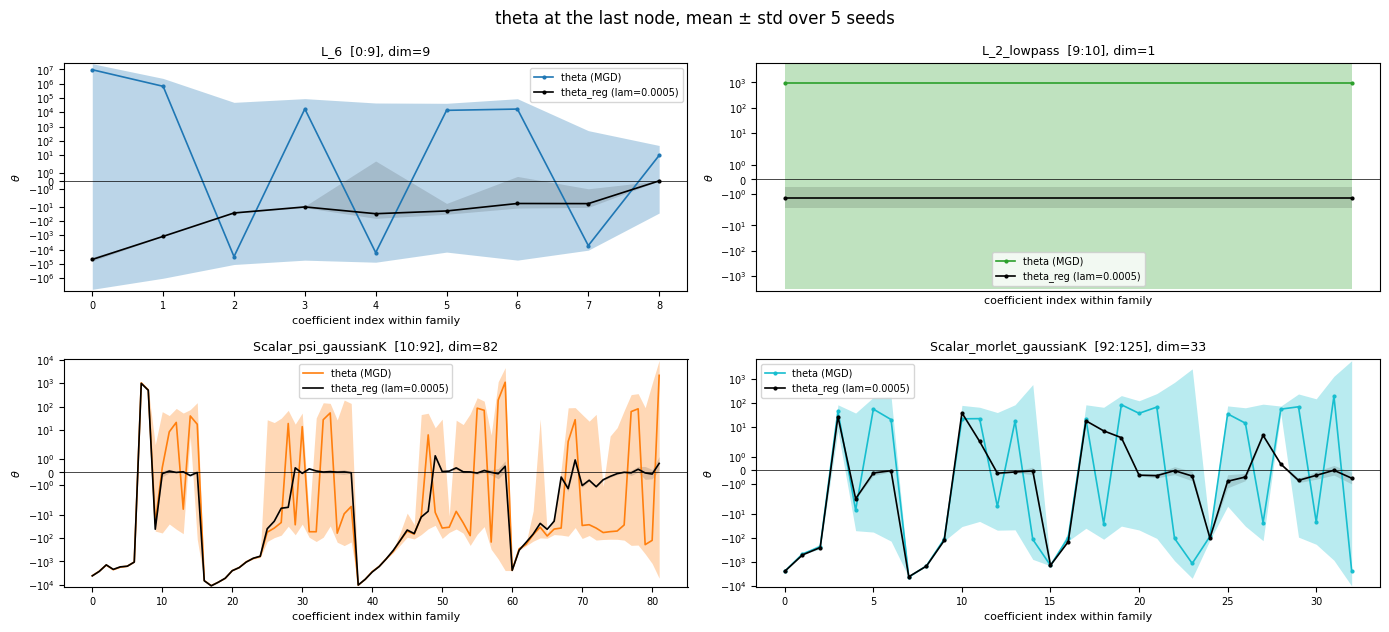

per-seed L_6 coefficients (theta_reg (lam=0.0005)):
[[-3.917e+04 -1.203e+03 -2.712e+01 -1.057e+01 -9.256e+01 -6.527e+00
  -7.630e+00 -1.300e+01 -1.637e-04]
 [-3.710e+04 -1.201e+03 -2.695e+01 -9.358e+00 -1.819e+01 -2.117e+01
  -1.302e+00 -7.293e-01 -1.704e-04]
 [-6.048e+04 -1.201e+03 -2.890e+01 -9.231e+00 -1.978e+01 -5.572e+00
  -1.667e+01 -9.681e+00 -2.650e-03]
 [-7.083e+04 -1.202e+03 -2.725e+01 -1.234e+01 -8.060e+00 -2.799e+01
  -1.609e+00 -3.622e+00 -1.547e-04]
 [-4.161e+04 -1.202e+03 -2.706e+01 -1.028e+01 -1.608e+01 -3.802e+01
  -2.555e+00 -3.335e+00 -1.717e-04]]
average across seeds:
[-4.98402540e+04 -1.20170900e+03 -2.74532364e+01 -1.03540419e+01
 -3.09348161e+01 -1.98575782e+01 -5.95323126e+00 -6.07425797e+00
 -6.62103848e-04]


In [40]:
def _saved(kind, config):
    """saved_results/<kind>/<config>[.pt], or None if neither exists."""
    p = root / 'saved_results' / kind / config
    return next((q for q in (p.with_name(p.name + '.pt'), p) if q.exists()), None)

theta_mgd_by_seed, theta_reg0_by_seed = {}, {}
for key in seed_keys:
    path = _saved('lagrange_multipliers', config_by_seed[key])
    assert path is not None, f'{key}: no saved_results/lagrange_multipliers/{config_by_seed[key]}[.pt]'
    theta_t = torch.load(path, map_location='cpu')
    theta_mgd_by_seed[key] = theta_t[-1].double().numpy()
    print(f"{key}: theta_t {tuple(theta_t.shape)} -> last step")
    del theta_t
    if HAVE_REG:
        theta_reg0_by_seed[key] = torch.load(theta_path_by_seed[key], map_location='cpu',
                                             weights_only=False)['Theta_reg'][-1].double().numpy()

theta_sets = {'theta (MGD)': np.stack([theta_mgd_by_seed[k] for k in seed_keys])}   # (n_seeds, d)
if HAVE_REG:
    theta_sets[f'theta_reg (lam={LAM:g})'] = np.stack([theta_reg0_by_seed[k] for k in seed_keys])
assert len({v.shape for v in theta_sets.values()}) == 1, {k: v.shape for k, v in theta_sets.items()}
d_theta = theta_sets['theta (MGD)'].shape[1]

_pots0 = load_potentials_for_config(exp_dir_by_seed[seed_keys[0]], cfg_by_seed[seed_keys[0]], device)
family_ranges0 = {name: (a, a + w) for name, (a, w) in theta_column_map(_pots0, d_theta).items()}
del _pots0

# (line alpha, band alpha): MGD opaque, theta_reg the same color but faded
STYLE = {'theta (MGD)': (1.0, 0.30), 'theta_reg': (1.0, 0.12)}
n_cols = 2
n_rows = math.ceil(len(family_ranges0) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(7 * n_cols, 3.2 * n_rows), squeeze=False)
for i, (F, (a, b)) in enumerate(family_ranges0.items()):
    ax = axes[i // n_cols][i % n_cols]
    color = potential_colors.get(F, f'C{i}')
    idx = np.arange(b - a)
    for label, th in theta_sets.items():
        is_reg = label.startswith('theta_reg')
        la, fa = STYLE['theta_reg' if is_reg else label]
        c = 'k' if is_reg else color
        mean = th[:, a:b].mean(0)
        std = th[:, a:b].std(0, ddof=1) if th.shape[0] > 1 else np.zeros(b - a)
        # a 1-coefficient family would give a zero-width band: widen it to +-0.3 around 0
        xs, mean, std = (np.array([-0.3, 0.3]), mean.repeat(2), std.repeat(2)) if b - a == 1 else (idx, mean, std)
        ax.plot(xs, mean, color=c, alpha=la, lw=1.2, marker='.' if b - a < 40 else None, ms=4, label=label)
        ax.fill_between(xs, mean - std, mean + std, color=c, alpha=fa, lw=0)
    if b - a == 1:
        ax.set_xticks([])
    ax.axhline(0, color='k', lw=0.5)
    ax.set_title(f'{F}  [{a}:{b}], dim={b - a}', fontsize=9)
    ax.set_xlabel('coefficient index within family', fontsize=8)
    ax.set_ylabel(r'$\theta$', fontsize=8)
    ax.tick_params(labelsize=7)
    ax.legend(fontsize=7)
    ax.set_yscale("symlog") 
for j in range(len(family_ranges0), n_rows * n_cols):
    axes[j // n_cols][j % n_cols].axis('off')
fig.suptitle(f'theta at the last node, mean ± std over {len(seed_keys)} seeds'
             + ('' if HAVE_REG else '  (no theta_reg: LAM unset or not solved)'))
fig.tight_layout(); plt.show()

# L_6 coefficients across seeds -- only meaningful once a lam has been picked and Theta_reg is loaded.
L6_label = next((k for k in theta_sets if k.startswith('theta_reg')), None)
if L6_label is not None:
    print(f'per-seed L_6 coefficients ({L6_label}):')
    print(np.array2string(theta_sets[L6_label][:, 0:9], precision=3))
    print('average across seeds:')
    print(np.array2string(theta_sets[L6_label][:, 0:9].mean(axis=0)))
else:
    print('L_6 coefficients printout: skipped (picking mode; set LAM in the knobs cell to see them)')


## Load Theta_reg (final node) and the fitted potentials, per seed

`Theta_reg[-1]` = the regularised θ at the last node of the grid (the two_phase grid is the same for every seed). `theta_t`/MGD is never used.

The fitted potentials are fitted on `x1`, the same for every seed, so they should agree across seeds. This is **checked**, not assumed: φ of each seed's potentials on the first `N_CHECK` signals is compared with the reference seed's. If they all agree, one `phi_X` is shared. Otherwise each seed gets its own `phi_X` (the rest of the notebook works either way).

In [41]:
THETA_SOURCE = 'theta_reg'      # 'theta_t': the sampler's last-step theta; 'theta_reg': offline Theta_reg[-1]
# Picking mode (LAM = None) has no Theta_reg files yet. Auto-fall-back to theta_t so phi_by_seed is still
# built downstream and the lam-picker cell can read lam-indexed Theta_reg files on its own.
if THETA_SOURCE == 'theta_reg' and not HAVE_REG:
    print('HAVE_REG=False: falling back to THETA_SOURCE=theta_t for this run (set LAM to switch to theta_reg)')
    THETA_SOURCE = 'theta_t'
N_CHECK = 200

theta_by_seed, potentials_by_seed = {}, {}
for key in seed_keys:
    if THETA_SOURCE == 'theta_t':
        theta_by_seed[key] = theta_mgd_by_seed[key]               # loaded in the theta-per-family cell
        print(f"{key}: theta_t[-1] from lagrange_multipliers")
    else:
        sol = torch.load(theta_path_by_seed[key], map_location='cpu', weights_only=False)
        assert sol['config'] == config_by_seed[key]
        theta_by_seed[key] = sol['Theta_reg'][-1].double().numpy()
        print(f"{key}: Theta_reg {tuple(sol['Theta_reg'].shape)}, lam={sol['lam']:g}, "
              f"residual {sol['residual']:.2e}, last node t = {float(sol['t_reg'][-1]):.8f}")
    potentials_by_seed[key] = load_potentials_for_config(exp_dir_by_seed[key], cfg_by_seed[key], device)

widths = {k: v.shape[0] for k, v in theta_by_seed.items()}
assert len(set(widths.values())) == 1, f'Theta_reg widths differ across seeds: {widths}'
reg_all_np = np.stack([theta_by_seed[k] for k in seed_keys])    # (n_seeds, n_features)
n_seeds, n_features = reg_all_np.shape
theta_reg_mean = reg_all_np.mean(0)
theta_reg_std = reg_all_np.std(0, ddof=1) if n_seeds > 1 else np.full(n_features, np.nan)
print(f"reg_all: {reg_all_np.shape} ({n_seeds} seeds, {n_features} features)")

REFERENCE_SEED = seed_keys[0]
potentials_ref = potentials_by_seed[REFERENCE_SEED]
col_map = theta_column_map(potentials_ref, n_features)    # raises if the widths do not add up to n_features
family_ranges = {name: (a, a + d) for name, (a, d) in col_map.items()}
for name, (a, b) in family_ranges.items():
    print(f"  {name:45s} [{a:4d}:{b:<4d}]  dim={b - a}")

x_check = x1[:N_CHECK]
phi_check_ref = compute_phi_X(potentials_ref, x_check).double()
phi_diff = {k: (compute_phi_X(potentials_by_seed[k], x_check).double() - phi_check_ref).abs().max().item()
            for k in seed_keys[1:]}
PHI_SHARED = all(d == 0 for d in phi_diff.values())
print(f"max |phi_seed - phi_{REFERENCE_SEED}| on {N_CHECK} signals: {phi_diff} -> "
      f"{'one phi_X shared by all seeds' if PHI_SHARED else 'fitted potentials differ: phi_X computed per seed'}")

seed900: Theta_reg (54998, 125), lam=0.0005, residual 7.14e-12, last node t = 0.99995000
[deduplicate_filters] filters_Q: 25 -> 22 channels for channel-list potentials (dropped duplicates [21, 22, 23], tol=1e-08)
seed901: Theta_reg (54998, 125), lam=0.0005, residual 4.47e-12, last node t = 0.99995000
[deduplicate_filters] filters_Q: 25 -> 22 channels for channel-list potentials (dropped duplicates [21, 22, 23], tol=1e-08)
seed902: Theta_reg (54998, 125), lam=0.0005, residual 9.13e-12, last node t = 0.99995000
[deduplicate_filters] filters_Q: 25 -> 22 channels for channel-list potentials (dropped duplicates [21, 22, 23], tol=1e-08)
seed903: Theta_reg (54998, 125), lam=0.0005, residual 7.76e-12, last node t = 0.99995000
[deduplicate_filters] filters_Q: 25 -> 22 channels for channel-list potentials (dropped duplicates [21, 22, 23], tol=1e-08)
seed904: Theta_reg (54998, 125), lam=0.0005, residual 6.56e-12, last node t = 0.99995000
[deduplicate_filters] filters_Q: 25 -> 22 channels for chan

## Across seeds variance: MGD vs REG 

5 seeds, 125 coefficients (0 with zero variance in MGD or REG, left out)
REG vs MGD across all 125 live coeffs: median gain = 147587.5x,  geomean gain = 85316.4x,  total-variance gain = 1118122.2x  (ratio REG/MGD: median 6.8e-06, geomean 1.2e-05)


,n coeffs,n live,median var MGD,median var REG,median REG/MGD,max REG/MGD,# REG > MGD
family,,,,,,,
L_6,9,9,5.22e+09,25.8,8.13e-09,9.05e-07,0
L_2_lowpass,1,1,1.8e+07,0.595,3.31e-08,3.31e-08,0
Scalar_psi_gaussianK,82,82,3.31e+03,0.0495,1.03e-05,0.115,0
Scalar_morlet_gaussianK,33,33,3.72e+03,0.0883,6.78e-06,0.0751,0
ALL,125,125,3.69e+03,0.0883,6.78e-06,0.115,0


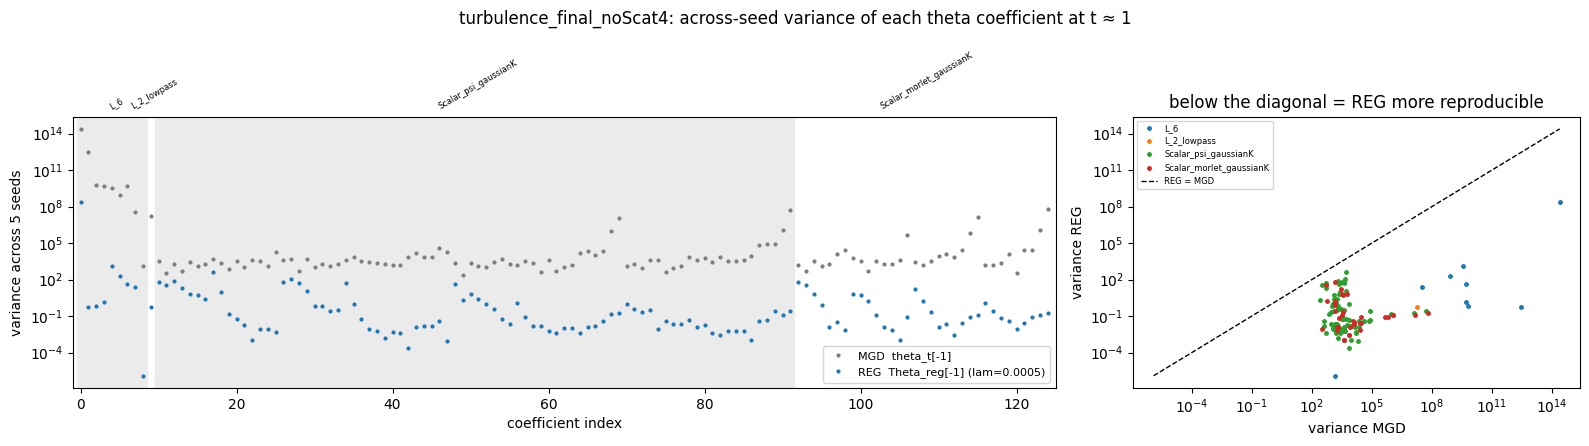

coefficients where REG variance > MGD variance: []


In [42]:
# --- Across-seed variance of each theta coefficient at t ≈ 1: MGD (theta_t[-1]) vs REG (Theta_reg[-1]) ---
assert THETA_SOURCE == 'theta_reg', 'theta_by_seed holds theta_t (no Theta_reg loaded): set LAM so HAVE_REG=True'

mgd_all = np.stack([theta_mgd_by_seed[k] for k in seed_keys])     # (n_seeds, n_features)
reg_all = np.stack([theta_by_seed[k] for k in seed_keys])         # (n_seeds, n_features)
var_mgd = mgd_all.var(0, ddof=1)
var_reg = reg_all.var(0, ddof=1)
live = (var_mgd > 0) & (var_reg > 0)                              # masked/dead coefficients are exactly 0 in every seed
ratio = np.full(n_features, np.nan)
ratio[live] = var_reg[live] / var_mgd[live]
print(f'{n_seeds} seeds, {n_features} coefficients ({(~live).sum()} with zero variance in MGD or REG, left out)')

# per-family summary
rows = []
for F, (a, b) in family_ranges.items():
    m = live[a:b]
    r = ratio[a:b][m]
    rows.append({'family': F, 'n coeffs': b - a, 'n live': int(m.sum()),
                 'median var MGD': np.median(var_mgd[a:b][m]) if m.any() else np.nan,
                 'median var REG': np.median(var_reg[a:b][m]) if m.any() else np.nan,
                 'median REG/MGD': np.median(r) if m.any() else np.nan,
                 'max REG/MGD': r.max() if m.any() else np.nan,
                 '# REG > MGD': int((r > 1).sum())})
r_all = ratio[live]
rows.append({'family': 'ALL', 'n coeffs': n_features, 'n live': int(live.sum()),
             'median var MGD': np.median(var_mgd[live]), 'median var REG': np.median(var_reg[live]),
             'median REG/MGD': np.median(r_all), 'max REG/MGD': r_all.max(), '# REG > MGD': int((r_all > 1).sum())})

r_all = ratio[live]
gain_median = 1 / np.median(r_all)                       # typical coefficient: variance ÷ this many
gain_geomean = np.exp(-np.mean(np.log(r_all)))           # fold-change interpretation (geo mean of 1/ratio)
gain_total = var_mgd[live].sum() / var_reg[live].sum()   # total-variance interpretation
print(f'REG vs MGD across all {live.sum()} live coeffs: '
      f'median gain = {gain_median:.1f}x,  geomean gain = {gain_geomean:.1f}x,  '
      f'total-variance gain = {gain_total:.1f}x  (ratio REG/MGD: median {np.median(r_all):.2g}, geomean {1/gain_geomean:.2g})')

var_tbl = pd.DataFrame(rows).set_index('family')
display(var_tbl.style.format({c: '{:.3g}' for c in ['median var MGD', 'median var REG', 'median REG/MGD', 'max REG/MGD']}))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={'width_ratios': [2.2, 1]})

# left: variance per coefficient index, families shaded
ax = axes[0]
idx = np.arange(n_features)
ax.semilogy(idx[live], var_mgd[live], '.', ms=4, color='tab:gray', label='MGD  theta_t[-1]')
ax.semilogy(idx[live], var_reg[live], '.', ms=4, color='tab:blue', label=f'REG  Theta_reg[-1] ({LAM_LABEL})')
for j, (F, (a, b)) in enumerate(family_ranges.items()):
    if j % 2 == 0:
        ax.axvspan(a - 0.5, b - 0.5, color='0.92', zorder=0)
    ax.text((a + b) / 2, 1.02, F, transform=ax.get_xaxis_transform(), ha='center', va='bottom',
            fontsize=6, rotation=30)
ax.set_xlim(-1, n_features)
ax.set_xlabel('coefficient index'); ax.set_ylabel(f'variance across {n_seeds} seeds')
ax.legend(fontsize=8, loc='lower right')

# right: REG variance vs MGD variance, one point per coefficient
ax = axes[1]
cmap = plt.get_cmap('tab10')
for j, (F, (a, b)) in enumerate(family_ranges.items()):
    m = live[a:b]
    ax.loglog(var_mgd[a:b][m], var_reg[a:b][m], '.', ms=5, color=cmap(j % 10), label=F)
lo = min(var_mgd[live].min(), var_reg[live].min()); hi = max(var_mgd[live].max(), var_reg[live].max())
ax.plot([lo, hi], [lo, hi], 'k--', lw=1, label='REG = MGD')
ax.set_xlabel('variance MGD'); ax.set_ylabel('variance REG')
ax.set_title('below the diagonal = REG more reproducible')
ax.legend(fontsize=6, loc='upper left')
fig.suptitle(f'{ARM}: across-seed variance of each theta coefficient at t ≈ 1'); fig.tight_layout(); plt.show()

bad = np.where(ratio > 1)[0]
print('coefficients where REG variance > MGD variance:',
      [(int(i), float(ratio[i]), float(var_mgd[i]), float(var_reg[i])) for i in bad])

## Whole-dataset rare/typical split

Method from `extract_samples.ipynb`: a signal is **rare** if its extremeness, $\max_t |x(t+1)-x(t)|$ (max absolute lag-1 increment), exceeds the `PERCENTILE`-th percentile (Knobs cell) of that quantity over the dataset. It is applied to `x1`: the wavelet-decomposed **and normalized** signals that `phi_X` is computed on. So the labels line up with `phi_X`, and the cutoff is in the same units as the model samples (section 6).

`normalize` (`codes/utils.py`) is **global**: one scalar mean and one scalar std for the whole tensor, not per sample. A positive rescaling preserves the ranking, so the split should match one on un-normalized `Data[:n1]`; only the cutoff value changes, by the factor `Data[:n1].std()`. The cell checks both.

In [43]:
def compute_acceleration(Data):
    """a(t) = Data(t+1) - Data(t), lag-1 velocity increment."""
    return Data[..., 1:] - Data[..., :-1]

def extract_rare_typical(Data, criterion='percentile', std_threshold=40,
                          sustained_sigma=10, min_exceedances=3, percentile=95):
    accel = compute_acceleration(Data)
    accel_std = accel.flatten().std(unbiased=True).item()
    B = accel.shape[0]
    reduce_dims = tuple(range(1, accel.ndim))
    per_traj_max_abs_accel = accel.abs().amax(dim=reduce_dims)

    if criterion == 'max_sigma':
        is_rare = per_traj_max_abs_accel > std_threshold * accel_std
        info = dict(accel_std=accel_std, threshold=std_threshold * accel_std)
    elif criterion == 'sustained_sigma':
        exceed_mask = accel.abs() > sustained_sigma * accel_std
        per_traj_exceed_count = exceed_mask.reshape(B, -1).sum(dim=1)
        is_rare = per_traj_exceed_count >= min_exceedances
        info = dict(accel_std=accel_std, threshold=sustained_sigma * accel_std,
                    min_exceedances=min_exceedances, exceed_counts=per_traj_exceed_count)
    elif criterion == 'percentile':
        cutoff = np.percentile(per_traj_max_abs_accel.cpu().numpy(), percentile)
        is_rare = per_traj_max_abs_accel > cutoff
        info = dict(accel_std=accel_std, percentile=percentile, cutoff=cutoff)
    else:
        raise ValueError(f"unknown criterion '{criterion}'")

    idx_rare = torch.nonzero(is_rare).flatten().tolist()
    idx_typical = torch.nonzero(~is_rare).flatten().tolist()
    return idx_typical, idx_rare, info

idx_typical, idx_rare, info_split = extract_rare_typical(x1, criterion='percentile', percentile=PERCENTILE)
category_indices = {'typical': idx_typical, 'rare': idx_rare}
category_colors = {'typical': 'tab:blue', 'rare': 'tab:red'}
rare_set = set(idx_rare)
cutoff_rare = info_split['cutoff']   # x1 (normalized) units
P_LABEL = f'p{PERCENTILE:g}'
print(f"Whole dataset (n1={n1}) split on x1 at {P_LABEL}: typical {len(idx_typical)}, rare {len(idx_rare)} | "
      f"cutoff = {cutoff_rare:.4g} in x1 units")

# Previous split, on un-normalized Data[:n1] -- only to report what changed.
_, idx_rare_old, info_old = extract_rare_typical(Data[:n1], criterion='percentile', percentile=PERCENTILE)
print(f"Old split on Data[:n1]: rare {len(idx_rare_old)}, cutoff (p{info_old['percentile']}) = "
      f"{info_old['cutoff']:.4g} in Data units | overlap with new rare set: "
      f"{len(set(idx_rare) & set(idx_rare_old))}/{len(idx_rare)} | cutoff ratio old/new = "
      f"{info_old['cutoff'] / cutoff_rare:.4g} vs Data[:n1].std() = {Data[:n1].std().item():.4g}")

Whole dataset (n1=10000) split on x1 at p99: typical 9900, rare 100 | cutoff = 0.5594 in x1 units
Old split on Data[:n1]: rare 100, cutoff (p99) = 1.774 in Data units | overlap with new rare set: 100/100 | cutoff ratio old/new = 3.172 vs Data[:n1].std() = 3.172


### What the rare/typical criterion does, and examples of each

For each signal $x$ in `x1` (one row: $M$ = 256 points, after the wavelet coarse-graining and the global normalization):

1. Take the jumps between neighbouring points, $\Delta x(t) = x(t+1) - x(t)$ for $t = 0,\dots,M-2$ (the lag-1 increments; the code calls them "acceleration", `compute_acceleration`). The jump from the last point back to the first is **not** included.
2. Keep only the biggest one in absolute value: the extremeness $e = \max_t |\Delta x(t)|$.
3. Compute $e$ for all `n1` signals. The cutoff is the `PERCENTILE`-th percentile of these values. Signals with $e$ **above** the cutoff are *rare* and all others are *typical*. So at `PERCENTILE = 95` exactly the 5% most extreme signals are rare (up to ties).

In words: a signal is rare if it contains **at least one unusually steep jump** somewhere. One steep jump is enough. The criterion looks only at steepness, not at how large the signal is or how often it jumps. A signal with a big but smooth excursion stays typical. Because `normalize` is global (one mean and std for the whole tensor), the ranking of $e$ and therefore the split are the same as on the raw data. Only the cutoff value changes units.

Below: the distribution of $e$ with the cutoff, then `N_EVENT_EXAMPLES` signals per category. The red dot marks where the biggest jump is.

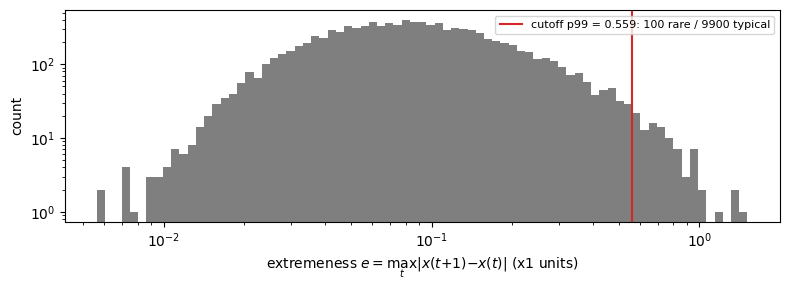

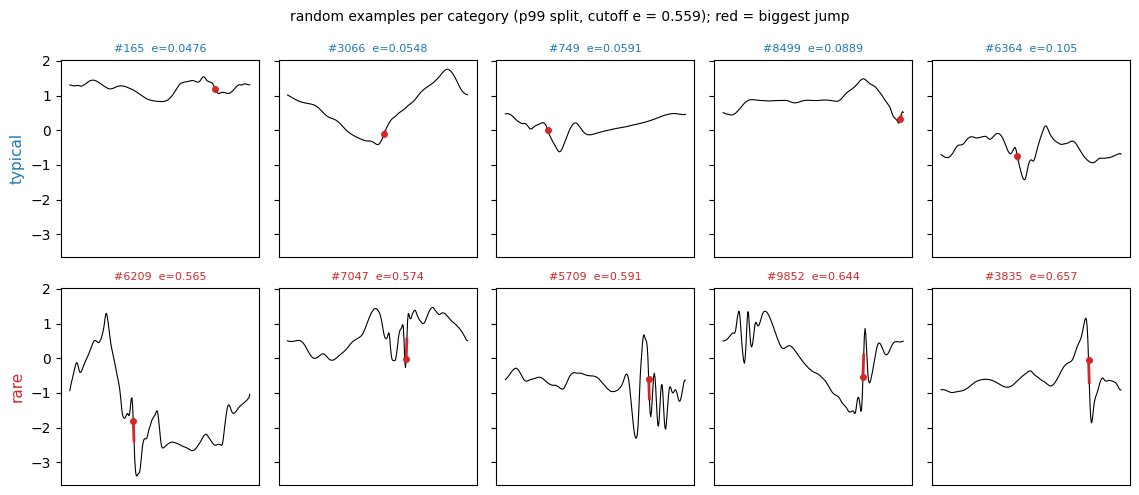

In [44]:
e_split = compute_acceleration(x1).abs().amax(dim=(1, 2)).cpu().numpy()        # (n1,) extremeness e
t_jump = compute_acceleration(x1).abs()[:, 0].argmax(dim=-1).cpu().numpy()    # where the biggest jump is
assert np.array_equal(np.sort(np.flatnonzero(e_split > cutoff_rare)), np.sort(idx_rare))

fig, ax = plt.subplots(figsize=(8, 3))
bins = np.logspace(np.log10(e_split.min()), np.log10(e_split.max()), 80)
ax.hist(e_split, bins=bins, color='tab:gray')
ax.axvline(cutoff_rare, color=category_colors['rare'], lw=1.5,
           label=f'cutoff {P_LABEL} = {cutoff_rare:.3g}: {len(idx_rare)} rare / {len(idx_typical)} typical')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel(r'extremeness $e = \max_t |x(t+1)-x(t)|$ (x1 units)'); ax.set_ylabel('count')
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

rng_ev = np.random.default_rng(EVENT_SEED)
picks = {}
for cat, idx in category_indices.items():
    idx = np.asarray(idx)
    k = min(N_EVENT_EXAMPLES, len(idx))
    if EVENT_PICK == 'extreme':   # rare: largest e; typical: smallest e
        order = np.argsort(e_split[idx])
        chosen = idx[order[::-1][:k]] if cat == 'rare' else idx[order[:k]]
    else:
        chosen = rng_ev.choice(idx, size=k, replace=False)
    picks[cat] = chosen[np.argsort(e_split[chosen])]          # left to right: increasing e

n_col = 5 #max(len(v) for v in picks.values())
fig, axes = plt.subplots(2, n_col, figsize=(2.3 * n_col, 5), sharey=True, squeeze=False)
for r, cat in enumerate(['typical', 'rare']):
    for c in range(n_col):
        ax = axes[r][c]
        if c >= len(picks[cat]):
            ax.axis('off'); continue
        i = picks[cat][c]
        sig = x1[i, 0].cpu().numpy()
        ax.plot(sig, lw=0.8, color='black')
        tj = t_jump[i]
        ax.plot([tj, tj + 1], sig[[tj, tj + 1]], color='tab:red', lw=2)
        ax.plot(tj, sig[tj], 'o', color='tab:red', ms=4)
        ax.set_title(f'#{i}  e={e_split[i]:.3g}', fontsize=8, color=category_colors[cat])
        ax.set_xticks([])
    axes[r][0].set_ylabel(cat, color=category_colors[cat], fontsize=11)
fig.suptitle(f"{EVENT_PICK} examples per category ({P_LABEL} split, cutoff e = {cutoff_rare:.3g}); "
             "red = biggest jump", fontsize=10)
fig.tight_layout(); plt.show()

## Per-family energy, split by category

Same `phi_X`/`family_energy`/`total_log_p_unnorm` as the pooled notebook, just indexed by `category_indices` afterward -- the underlying $\theta^\top\varphi(x)$ computation is identical, only the grouping changes.

**Sign convention** (checked in `sde_routines.py`: the sampler ascends $+\nabla_x\,\theta^\top\varphi$): $p_\theta(x)\propto\exp(+\theta^\top\varphi(x))$, so $\theta^\top\varphi(x)=\log p_\theta(x)+\log Z(\theta)$.
Every "log p contribution" below is $\theta_F^\top\varphi_F(x)$ in this convention: higher means more likely.

In [45]:
phi_X = compute_phi_X(potentials_ref, x1).detach().cpu().double().numpy()   # (n1, n_features)
assert phi_X.shape == (n1, n_features), phi_X.shape
phi_by_seed = {k: phi_X if (PHI_SHARED or k == REFERENCE_SEED)
               else compute_phi_X(potentials_by_seed[k], x1).detach().cpu().double().numpy()
               for k in seed_keys}

ranges_with_total = {**family_ranges, 'TOTAL': (0, n_features)}
# C[F]: (n_seeds, n1) -- per-seed, per-signal log p contribution (nats) of family F
C = {F: np.stack([phi_by_seed[k][:, a:b] @ reg_all_np[s, a:b] for s, k in enumerate(seed_keys)])
     for F, (a, b) in ranges_with_total.items()}
# Seed-averaged contribution; with a shared phi_X this is exactly theta_reg_mean . phi(x)
C_bar = {F: C[F].mean(0) for F in C}
family_energy = {F: C_bar[F] for F in family_ranges}
total_log_p_unnorm = C_bar['TOTAL']

comparison = []
for category, idx in category_indices.items():
    for name in ranges_with_total:
        sample_totals = C_bar[name][idx]
        comparison.append({
            'category': category, 'family': name,
            'mean_total': sample_totals.mean(), 'std_total': sample_totals.std(ddof=1),
        })
comparison_df = pd.DataFrame(comparison)
print('seed-averaged theta; std_total = spread across signals')
display(comparison_df.pivot(index='family', columns='category', values=['mean_total', 'std_total']))

seed-averaged theta; std_total = spread across signals


mean_total         std_total        
category                      rare typical      rare typical
family                                                      
L_2_lowpass                 -0.997    -1.1      1.26    1.58
L_6                         -0.102 -0.0212     0.162  0.0853
Scalar_morlet_gaussianK       -180    -101      38.3    33.4
Scalar_psi_gaussianK          -511    -279       110    99.5
TOTAL                         -692    -381       144     131

In [46]:
from scipy import stats
lp = np.stack([phi_by_seed[k] @ theta_by_seed[k] for k in seed_keys])   # (n_seeds, n1), log p unnormalised
iu = np.triu_indices(len(seed_keys), 1)
Cc = np.corrcoef(lp); np.fill_diagonal(Cc, np.nan)
c = Cc[iu]    
print(pd.Series(np.nanmean(Cc, 1), index=seed_keys, name='mean corr with others').sort_values().head(10))
rho = np.atleast_2d(stats.spearmanr(lp, axis=1).correlation)[iu]
print(f'{ARM}, L_6<0, lam={LAM:g}, {len(seed_keys)} seeds, {lp.shape[1]} signals')
print(f'  corr median {np.median(c):.3f}, min {c.min():.3f} | Spearman median {np.median(rho):.3f}')
print(f'  seed spread / signal spread {lp.std(0, ddof=1).mean() / lp.mean(0).std(ddof=1):.3f}')

seed902   1
seed901   1
seed904   1
seed900   1
seed903   1
Name: mean corr with others, dtype: float64
turbulence_final_noScat4, L_6<0, lam=0.0005, 5 seeds, 10000 signals
  corr median 1.000, min 1.000 | Spearman median 1.000
  seed spread / signal spread 0.005


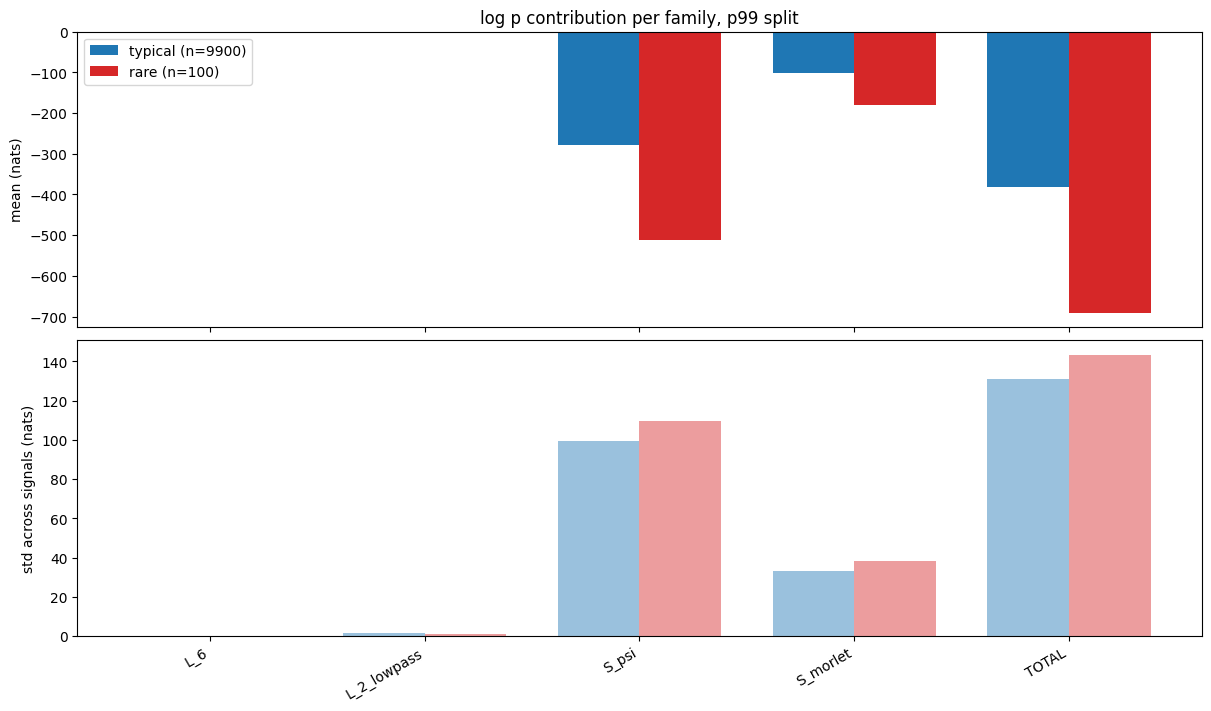

In [47]:
from matplotlib.colors import to_rgba

short = lambda F: F.replace('Scalar_', 'S_').replace('_gaussianK', '')
categories = list(category_indices.keys())
family_names = list(ranges_with_total.keys())   # all families + TOTAL
cat_stats = comparison_df.set_index(['category', 'family'])   # not called `stats`: that name is scipy.stats below
means = {c: cat_stats.loc[c].loc[family_names, 'mean_total'].to_numpy() for c in categories}
stds = {c: cat_stats.loc[c].loc[family_names, 'std_total'].to_numpy() for c in categories}
n_cat = {c: len(category_indices[c]) for c in categories}
width = 0.38
offsets = {c: (i - (len(categories) - 1) / 2) * width for i, c in enumerate(categories)}

# Full range: all families on one axis (the L_6 / Scalar families set the scale)
x = np.arange(len(family_names))
fig, (ax_mean, ax_std) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, constrained_layout=True)
for c in categories:
    ax_mean.bar(x + offsets[c], means[c], width, color=category_colors[c], label=f'{c} (n={n_cat[c]})')
    ax_std.bar(x + offsets[c], stds[c], width, color=to_rgba(category_colors[c], 0.45), label=c)
ax_mean.axhline(0, color='k', lw=0.6)
ax_mean.set_ylabel('mean (nats)'); ax_std.set_ylabel('std across signals (nats)')
ax_std.set_xticks(x); ax_std.set_xticklabels([short(F) for F in family_names], rotation=30, ha='right')
ax_mean.set_title(f'log p contribution per family, {P_LABEL} split'); ax_mean.legend()
plt.show()

## log p, typical vs rare

$\theta^\top\varphi(x)$ = $\log p_\theta(x)$ up to the additive constant $-\log Z(\theta)$ -- the SAME constant for both categories (same $\theta$), so shape and the gap between them are exact; only the absolute axis position is unknown.

typical: gumbel_r: loc=-450, scale=146.4, loglik=-6.39e+04, KS D=0.112 | gumbel_l: loc=-319.4, scale=111.8, loglik=-6.209e+04, KS D=0.0235  -> best: gumbel_l
rare: gumbel_r: loc=-766.7, scale=160.5, loglik=-654.5, KS D=0.122 | gumbel_l: loc=-624.3, scale=121.6, loglik=-635.6, KS D=0.0635  -> best: gumbel_l


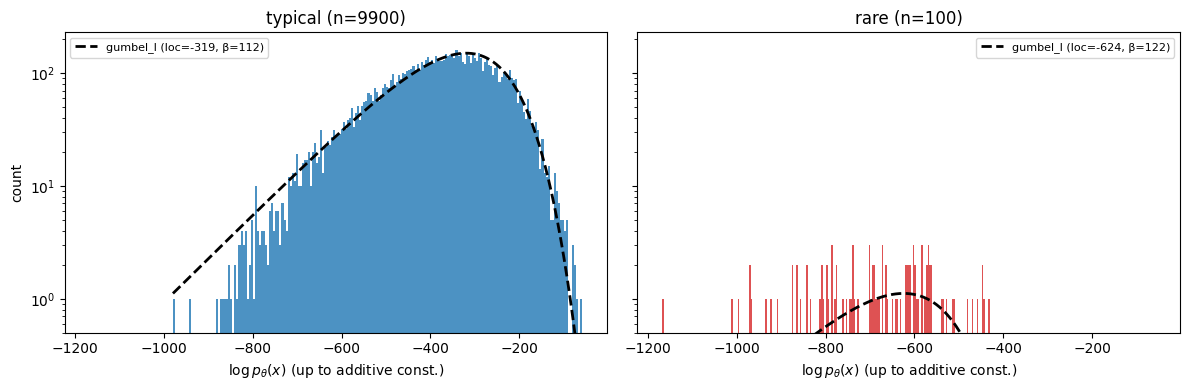

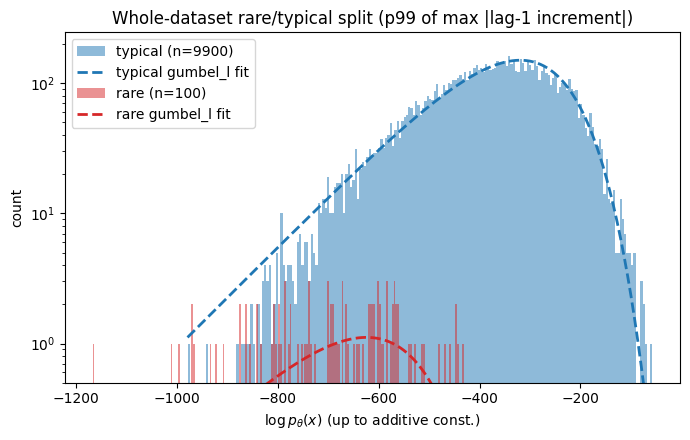

mean log p_theta, up to the same additive constant: typical = -381.4, rare = -691.8  ->  rare < typical: True


In [48]:
from scipy import stats

def _to_np(x):
    return x.detach().cpu().numpy().astype(float) if hasattr(x, 'detach') else np.asarray(x, dtype=float)

logp_by_category = {category: _to_np(total_log_p_unnorm[idx]) for category, idx in category_indices.items()}

# --- Gumbel fit per category: try both orientations, keep the better one by log-likelihood ---
gumbel_fits = {}
for category, x in logp_by_category.items():
    candidates = {}
    for name, dist in (('gumbel_r', stats.gumbel_r), ('gumbel_l', stats.gumbel_l)):
        loc, scale = dist.fit(x)
        candidates[name] = dict(dist=dist, loc=loc, scale=scale,
                                loglik=dist.logpdf(x, loc, scale).sum(),
                                ks=stats.kstest(x, dist.cdf, args=(loc, scale)).statistic)
    best = max(candidates, key=lambda k: candidates[k]['loglik'])
    gumbel_fits[category] = {**candidates[best], 'kind': best}
    print(f"{category}: " + " | ".join(
        f"{k}: loc={c['loc']:.4g}, scale={c['scale']:.4g}, loglik={c['loglik']:.4g}, KS D={c['ks']:.3g}"
        for k, c in candidates.items()) + f"  -> best: {best}")

def _overlay_gumbel(ax, x, edges, fit, color, label=None):
    grid = np.linspace(edges[0], edges[-1], 400)
    bin_width = edges[1] - edges[0]
    ax.plot(grid, fit['dist'].pdf(grid, fit['loc'], fit['scale']) * len(x) * bin_width,
            color=color, lw=2, ls='--', label=label)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
for ax, (category, logp) in zip(axes, logp_by_category.items()):
    color = category_colors.get(category, 'tab:gray')
    _, edges, _ = ax.hist(logp, bins=200, color=color, alpha=0.8)
    fit = gumbel_fits[category]
    _overlay_gumbel(ax, logp, edges, fit, 'k',
                    label=f"{fit['kind']} (loc={fit['loc']:.3g}, β={fit['scale']:.3g})")
    ax.set_title(f'{category} (n={len(logp)})')
    ax.set_xlabel(r'$\log p_\theta(x)$ (up to additive const.)')
    ax.set_yscale('log')
    ax.set_ylim(bottom=0.5)   # keep the pdf's far tail from stretching the log axis
    ax.legend(fontsize=8)
axes[0].set_ylabel('count')
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
for category, logp in logp_by_category.items():
    color = category_colors.get(category, 'tab:gray')
    _, edges, _ = ax.hist(logp, bins=200, color=color, alpha=0.5, label=f'{category} (n={len(logp)})')
    _overlay_gumbel(ax, logp, edges, gumbel_fits[category], color,
                    label=f"{category} {gumbel_fits[category]['kind']} fit")
ax.set_xlabel(r'$\log p_\theta(x)$ (up to additive const.)')
ax.set_ylabel('count')
ax.set_yscale('log')
ax.set_ylim(bottom=0.5)
ax.legend()
ax.set_title(f'Whole-dataset rare/typical split ({P_LABEL} of max |lag-1 increment|)')
fig.tight_layout()
plt.show()

mean_logp = {category: logp.mean() for category, logp in logp_by_category.items()}
print("mean log p_theta, up to the same additive constant: "
      + ", ".join(f"{category} = {m:.4g}" for category, m in mean_logp.items())
      + f"  ->  rare < typical: {mean_logp['rare'] < mean_logp['typical']}")

all: gumbel_r: loc=-455.2, scale=157, loglik=-6.506e+04, KS D=0.125 | gumbel_l: loc=-321.2, scale=113.5, loglik=-6.29e+04, KS D=0.021  -> best: gumbel_l


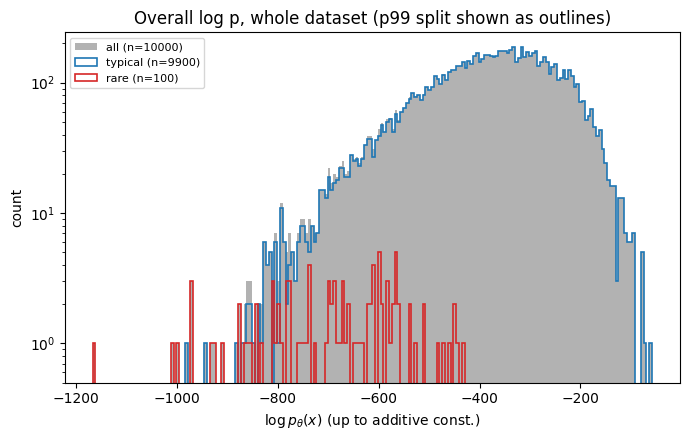

In [49]:
# --- Overall log p over all n1 signals (typical + rare together), with Gumbel fit ---
logp_all = _to_np(total_log_p_unnorm)

cands = {}
for name, dist in (('gumbel_r', stats.gumbel_r), ('gumbel_l', stats.gumbel_l)):
    loc, scale = dist.fit(logp_all)
    cands[name] = dict(dist=dist, loc=loc, scale=scale,
                       loglik=dist.logpdf(logp_all, loc, scale).sum(),
                       ks=stats.kstest(logp_all, dist.cdf, args=(loc, scale)).statistic)
best = max(cands, key=lambda k: cands[k]['loglik'])
fit_all = {**cands[best], 'kind': best}
print("all: " + " | ".join(f"{k}: loc={c['loc']:.4g}, scale={c['scale']:.4g}, "
                           f"loglik={c['loglik']:.4g}, KS D={c['ks']:.3g}" for k, c in cands.items())
      + f"  -> best: {best}")

fig, ax = plt.subplots(figsize=(7, 4.5))
_, edges, _ = ax.hist(logp_all, bins=200, color='tab:gray', alpha=0.6, label=f'all (n={len(logp_all)})')
for category, logp in logp_by_category.items():          # same bins, outlines only
    ax.hist(logp, bins=edges, histtype='step', lw=1.2,
            color=category_colors.get(category, 'k'), label=f'{category} (n={len(logp)})')
# _overlay_gumbel(ax, logp_all, edges, fit_all, 'k',
#                 label=f"{fit_all['kind']} fit (loc={fit_all['loc']:.3g}, β={fit_all['scale']:.3g})")
ax.set_xlabel(r'$\log p_\theta(x)$ (up to additive const.)')
ax.set_ylabel('count')
ax.set_yscale('log'); ax.set_ylim(bottom=0.5)
ax.set_title(f'Overall log p, whole dataset ({P_LABEL} split shown as outlines)')
ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

The printed line above says whether rare events sit at lower $\log p_\theta$ (seed-averaged θ) than typical ones for these runs. The gap between the two means is exact, because $\log Z(\theta)$ is the same for both.

In [50]:
# --- Physical sign check of log p (2026-10-05)
# Paste after the per-family energy cell (uses compute_phi_X, potentials_ref, reg_all_np, x1, total_log_p_unnorm).
# log p must DROP when (1) white noise is added to the data and (2) the data amplitude grows (alpha > 1), and
# RISE when the amplitude shrinks (alpha < 1): the density is highest for small, quiet signals (the data sit where
# the probability MASS is, not at the peak of the density -- as Guth's constant image is the most probable);
# (3) white noise with the data variance must sit far LEFT of the data histogram, a constant signal to the right.
# A flipped sign would show the opposite on all three.
N_SIG = 300                                        # data signals used (a random subset)
rng_c = np.random.default_rng(1)
sub = torch.as_tensor(rng_c.choice(x1.shape[0], N_SIG, replace=False))
xs = x1[sub].to(x1.device)
theta_bar = reg_all_np.mean(0)                     # seed-averaged theta (as total_log_p_unnorm)
logp = lambda x: compute_phi_X(potentials_ref, x).double().numpy() @ theta_bar
lp0 = logp(xs)                                     # log p of the unperturbed signals
sd_data = float(x1.std())

print('(1) white noise added (std = level x data std): median change of log p over the signals')
noise = torch.randn_like(xs)
for level in (0.01, 0.03, 0.1, 0.3, 1.0):
    d = logp(xs + level * sd_data * noise) - lp0
    print(f'   level {level:5.2f}: median {np.median(d):12.4g}   fraction of signals where log p dropped: {np.mean(d < 0):.2f}')

print('(2) amplitude x alpha: median log p(alpha x) - log p(x)  (should DECREASE with alpha: > 0 below 1, < 0 above)')
alphas = [0.25, 0.5, 0.8, 0.9, 1.0, 1.1, 1.25, 2.0, 4.0]
med = [np.median(logp(a * xs) - lp0) for a in alphas]
for a, m in zip(alphas, med):
    print(f'   alpha {a:4.2f}: {m:12.4g}')
print(f'   -> decreasing in alpha: {all(a > b for a, b in zip(med, med[1:]))}')

print("(3) Guth's arrows, against the data's log p (all n1 signals)")
lp_all = np.asarray(total_log_p_unnorm, dtype=float)
wn = logp(torch.randn_like(xs[:50]) * sd_data)
cst = logp(torch.zeros_like(xs[:1]))
print(f'   data log p: min {lp_all.min():.4g}, median {np.median(lp_all):.4g}, max {lp_all.max():.4g}')
print(f'   white noise (data std): median {np.median(wn):.4g}  -> below every data signal: {wn.max() < lp_all.min()}')
print(f'   constant zero signal: {cst[0]:.4g}  -> above the data median: {cst[0] > np.median(lp_all)}')

(1) white noise added (std = level x data std): median change of log p over the signals
   level  0.01: median       -745.3   fraction of signals where log p dropped: 1.00
   level  0.03: median        -1189   fraction of signals where log p dropped: 1.00
   level  0.10: median        -1904   fraction of signals where log p dropped: 1.00
   level  0.30: median        -3075   fraction of signals where log p dropped: 1.00
   level  1.00: median   -2.995e+04   fraction of signals where log p dropped: 1.00
(2) amplitude x alpha: median log p(alpha x) - log p(x)  (should DECREASE with alpha: > 0 below 1, < 0 above)
   alpha 0.25:        250.8
   alpha 0.50:          148
   alpha 0.80:         52.5
   alpha 0.90:        25.34
   alpha 1.00:            0
   alpha 1.10:       -23.65
   alpha 1.25:       -56.43
   alpha 2.00:       -185.4
   alpha 4.00:       -405.8
   -> decreasing in alpha: True
(3) Guth's arrows, against the data's log p (all n1 signals)
   data log p: min -1168, median -369

In [51]:
# --- Which family makes log p RISE at noise level ~0.3?  (2026-10-06)
phi0 = compute_phi_X(potentials_ref, xs).double().numpy()
rows = []
for level in (0.1, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0):
    dphi = compute_phi_X(potentials_ref, xs + level * sd_data * noise).double().numpy() - phi0
    rows.append({'level': level, **{F: np.median(dphi[:, a:b] @ theta_bar[a:b]) for F, (a, b) in family_ranges.items()},
                 'TOTAL': np.median(dphi @ theta_bar)})
print('median change of each family\'s log p contribution (nats); medians do not add up to TOTAL exactly')
display(pd.DataFrame(rows).set_index('level'))

median change of each family's log p contribution (nats); medians do not add up to TOTAL exactly


,L_6,L_2_lowpass,Scalar_psi_gaussianK,Scalar_morlet_gaussianK,TOTAL
level,,,,,
0.1,-0.0247,0.000404,-1.4e+03,-508,-1.9e+03
0.15,-0.282,0.000589,-1.67e+03,-587,-2.25e+03
0.2,-1.58,0.000712,-1.9e+03,-658,-2.55e+03
0.3,-18,0.000969,-2.26e+03,-788,-3.08e+03
0.5,-385,0.00123,-2.84e+03,-1e+03,-4.24e+03
0.7,-2.9e+03,0.001,-3.3e+03,-1.17e+03,-7.38e+03
1,-2.47e+04,0.000742,-3.87e+03,-1.38e+03,-3e+04


## Florentin's plot

Data signals ordered by $\log p_\theta$ (up to the constant), from least to most likely. The $\log p$ distribution has heavy outlier tails, so examples spaced **linearly** in $\log p$ fall mostly in empty tail regions. There the nearest signal is the same one several times, which gave duplicates. The default (`EXAMPLE_SPACING = 'quantile'`) spaces them equally in **rank** instead: panel $k$ is the signal at the $k$-th quantile within `EXAMPLE_RANGE`, so every panel is a distinct signal. The strip on top shows where the chosen examples sit in the $\log p$ histogram. Titles are red for rare and blue for typical signals.

In [52]:
# --- Florentin's plot (signals ordered by log p) ---
N_EXAMPLES = 16                  # wraps at 8 per row
EXAMPLE_SPACING = 'linear'     # 'quantile': equally spaced in rank of log p (every panel a distinct signal,
                                 #   insensitive to outliers); 'linear': equally spaced in log p value
EXAMPLE_RANGE = (0.05, 99.95)      # percentiles of log p the examples are drawn from; (0, 100) = full range
EXAMPLE_SHAREY = True            # same y-axis for every panel

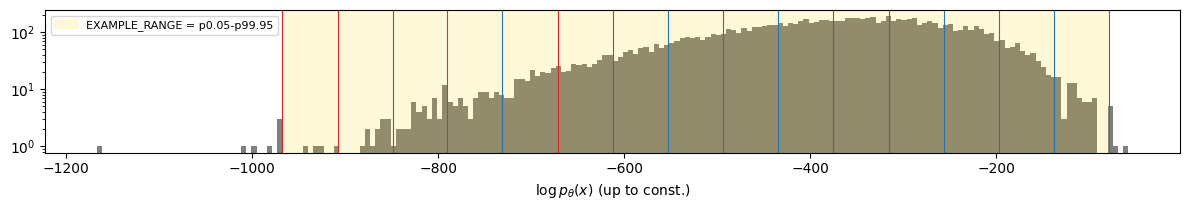

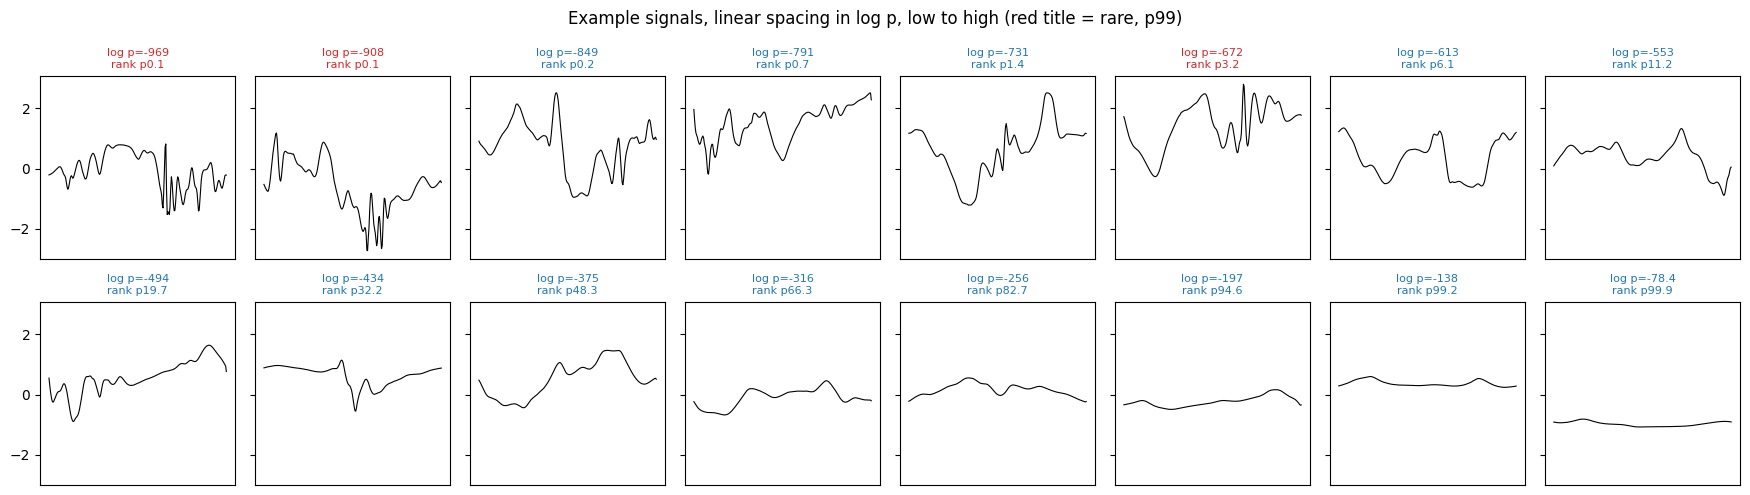

In [53]:
logp_all = np.asarray(total_log_p_unnorm, dtype=float)
lo_q, hi_q = EXAMPLE_RANGE
order = np.argsort(logp_all)                                   # signal indices, low to high log p
rank_lo, rank_hi = (int(round(q / 100 * (n1 - 1))) for q in (lo_q, hi_q))
if EXAMPLE_SPACING == 'quantile':
    ranks = np.unique(np.linspace(rank_lo, rank_hi, N_EXAMPLES).round().astype(int))
    example_idx = order[ranks]
elif EXAMPLE_SPACING == 'linear':
    targets = np.linspace(logp_all[order[rank_lo]], logp_all[order[rank_hi]], N_EXAMPLES)
    nearest = [int(np.argmin(np.abs(logp_all - t))) for t in targets]
    example_idx = np.array(list(dict.fromkeys(nearest)))      # drop repeats, keep order
    if len(example_idx) < N_EXAMPLES:
        print(f"linear spacing: {N_EXAMPLES - len(example_idx)} targets hit an already-shown signal, dropped")
else:
    raise ValueError(f"EXAMPLE_SPACING must be 'quantile' or 'linear', got {EXAMPLE_SPACING!r}")
rank_of = np.empty(n1, dtype=int); rank_of[order] = np.arange(n1)

# Where the examples sit in the log p distribution
fig, ax = plt.subplots(figsize=(12, 2.2))
ax.hist(logp_all, bins=200, color='tab:gray')
for i in example_idx:
    ax.axvline(logp_all[i], color=category_colors['rare' if i in rare_set else 'typical'], lw=0.8)
ax.axvspan(logp_all[order[rank_lo]], logp_all[order[rank_hi]], color='gold', alpha=0.15,
           label=f'EXAMPLE_RANGE = p{lo_q:g}-p{hi_q:g}')
ax.set_yscale('log'); ax.set_xlabel(r'$\log p_\theta(x)$ (up to const.)'); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

n_cols = 8
n_rows = math.ceil(len(example_idx) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.2 * n_cols, 2.5 * n_rows), sharey=EXAMPLE_SHAREY, squeeze=False)
for k, i in enumerate(example_idx):
    ax = axes[k // n_cols][k % n_cols]
    ax.plot(x1[i, 0].cpu().numpy(), lw=0.8, color='black')
    ax.set_title(f'log p={logp_all[i]:.3g}\nrank p{100 * rank_of[i] / (n1 - 1):.1f}', fontsize=8,
                 color=category_colors['rare' if i in rare_set else 'typical'])
    ax.set_xticks([])
for j in range(len(example_idx), n_rows * n_cols):
    axes[j // n_cols][j % n_cols].axis('off')
fig.suptitle(f'Example signals, {EXAMPLE_SPACING} spacing in log p, low to high (red title = rare, {P_LABEL})')
fig.tight_layout(); plt.show()

## Effective wavelet dimension vs -log p 

Parseval ||c||^2 / ||x||^2: median=1 (1.0 = exact; coefs shape (10000, 256), T=256)


,PR mean,PR min,PR max,normalized PR^2 mean,Pearson r,Spearman rho,rho (typical),rho (rare)
0,7.38,1.15,45.2,0.0288,0.483,0.454,0.445,0.344


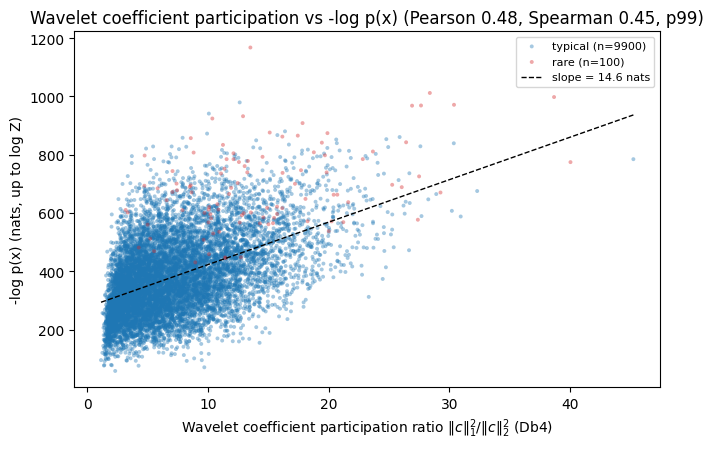

In [54]:
# Hypothesis: signals whose energy is distributed across more wavelet
# coefficients have lower log p.
# Uses an orthonormal Daubechies basis (Parseval -> energy accounting).
# The normalized participation ratio is
#   PR^2(x) = ||c||_1^2 / (d * ||c||_2^2), in [1/d, 1].
# The unnormalized participation ratio is
#   PR(x) = ||c||_1^2 / ||c||_2^2, in [1, d].
# Lower PR means more concentrated coefficient magnitudes;
# higher PR means more distributed coefficient magnitudes.

from ortho_wavelet.ReadyToUseWavelets import Db_wavelets
from scipy.stats import spearmanr, pearsonr

WAVELET_M = 4  # Daubechies order (Db4)

# --- 1. Full orthogonal wavelet pyramid on every signal ------------------
wavelet = Db_wavelets(m=WAVELET_M, device=x1.device, mode='Periodic')
T = x1.shape[-1]
J = int(np.floor(np.log2(T)))

x_in = x1.reshape(x1.shape[0], x1.shape[-1])
a = x_in
blocks = []

with torch.no_grad():
    for _ in range(J):
        d, a = wavelet.decompose(a)
        blocks.append(d.detach().cpu().double().numpy())
    blocks.append(a.detach().cpu().double().numpy())

coefs = np.concatenate(blocks, axis=-1)
assert coefs.shape[0] == n1, (coefs.shape, n1)

# Parseval sanity check
e_x = (x1.detach().cpu().double().numpy() ** 2).sum(axis=-1)
e_c = (coefs ** 2).sum(axis=-1)
print(
    f"Parseval ||c||^2 / ||x||^2: "
    f"median={np.median(e_c / e_x):.4g} "
    f"(1.0 = exact; coefs shape {coefs.shape}, T={T})"
)

# --- 2. Wavelet coefficient participation ratio --------------------------
l1 = np.abs(coefs).sum(axis=-1)
l2sq = (coefs ** 2).sum(axis=-1)
d_wav = coefs.shape[-1]

pr2 = l1 ** 2 / (d_wav * l2sq)  # normalized participation ratio
pr = l1 ** 2 / l2sq             # unnormalized participation ratio

# --- 3. -log p(x) from the already-computed total contribution -----------
neg_log_p = -np.asarray(total_log_p_unnorm, dtype=float)

# --- 4. Correlation summary ----------------------------------------------
rp, _ = pearsonr(pr, neg_log_p)
rs, _ = spearmanr(pr, neg_log_p)

row = {
    'PR mean': pr.mean(),
    'PR min': pr.min(),
    'PR max': pr.max(),
    'normalized PR^2 mean': pr2.mean(),
    'Pearson r': rp,
    'Spearman rho': rs,
}

for cat, idx in category_indices.items():
    row[f'rho ({cat})'] = spearmanr(pr[idx], neg_log_p[idx])[0]

corr_df = pd.DataFrame([row])
display(corr_df)

# --- 5. Scatter: participation ratio vs -log p ---------------------------
fig, ax = plt.subplots(figsize=(6.8, 4.6))

for cat, idx in category_indices.items():
    ax.scatter(
        pr[idx], neg_log_p[idx],
        s=8, alpha=0.4,
        color=category_colors[cat],
        label=f'{cat} (n={len(idx)})',
        edgecolors='none',
    )

slope, intercept = np.polyfit(pr, neg_log_p, 1)
xs = np.linspace(pr.min(), pr.max(), 50)

ax.plot(
    xs, slope * xs + intercept, 'k--', lw=1,
    label=f'slope = {slope:.3g} nats',
)

ax.set_ylabel('-log p(x) (nats, up to log Z)')
ax.set_xlabel(
    f'Wavelet coefficient participation ratio '
    f'$\\|c\\|_1^2 / \\|c\\|_2^2$ (Db{WAVELET_M})'
)
ax.set_title(
    f'Wavelet coefficient participation vs -log p(x) '
    f'(Pearson {rp:.2f}, Spearman {rs:.2f}, {P_LABEL})'
)
ax.legend(fontsize=8, loc='best')
fig.tight_layout()
plt.show()

## 1. Per-seed family contributions with error bars

For each seed $s$, `C[F][s, i]` $=\theta_{s,F}^\top\varphi_F(x_i)$ (log p contribution, nats), and `D[s, F]` = mean of `C[F][s]` over rare minus mean over typical. The table gives the mean/std of `D` across seeds, plus a bootstrap SE over the `len(idx_rare)` rare signals (resampled with the seed-averaged `C`; typical held fixed). The counts are printed below.

sum(family D) - TOTAL D = 9.663e-13  (should be ~0)
D over 5 seeds; bootstrap: 1000 resamples of the 100 rare signals (typical, n=9900, held fixed)


,family,mean_D,std_D_across_seeds,bootstrap_SE_rare
0,L_6,-0.0812,0.0274,0.0155
1,L_2_lowpass,0.099,0.0571,0.123
2,Scalar_psi_gaussianK,-232,1.21,10.7
3,Scalar_morlet_gaussianK,-78.5,0.998,3.66
4,TOTAL,-310,0.407,13.9


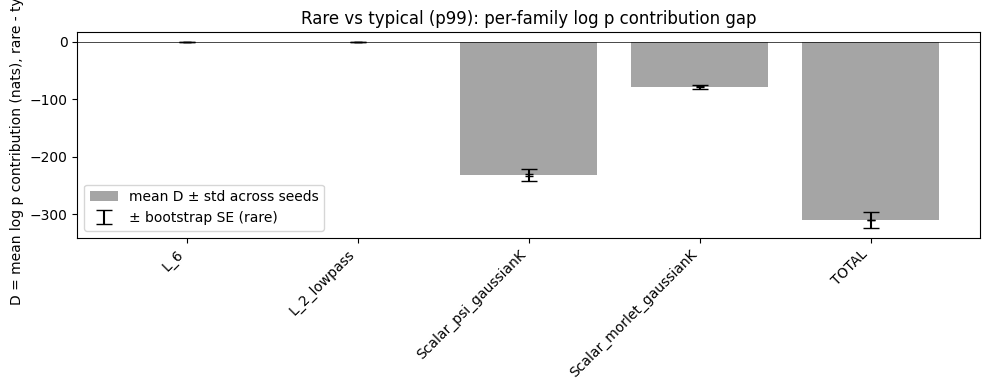

In [55]:
family_names_all = list(ranges_with_total.keys())  # all families + TOTAL
# C[F] (n_seeds, n1) and C_bar[F] (n1,) are built in the per-family energy cell above

D = np.stack([C[F][:, idx_rare].mean(axis=1) - C[F][:, idx_typical].mean(axis=1)
              for F in family_names_all], axis=1)  # (n_seeds, n_families+1)
D_mean = D.mean(axis=0)
D_std = D.std(axis=0, ddof=1) if n_seeds > 1 else np.full(D.shape[1], np.nan)

# sanity check: C[TOTAL] = sum_F C[F] exactly (linear), so D[TOTAL] should equal sum_F D[F]
total_i = family_names_all.index('TOTAL')
family_sum = sum(D_mean[i] for i, F in enumerate(family_names_all) if F != 'TOTAL')
print(f"sum(family D) - TOTAL D = {family_sum - D_mean[total_i]:.3e}  (should be ~0)")

# Bootstrap SE over the rare signals only (typical held fixed), using the
# seed-averaged C_bar.
rng = np.random.default_rng(BOOT_SEED)
n_boot = N_BOOT
idx_rare_arr = np.array(idx_rare)
typical_mean = {F: C_bar[F][idx_typical].mean() for F in family_names_all}
boot_D = np.empty((n_boot, len(family_names_all)))
for b in range(n_boot):
    resample = rng.choice(idx_rare_arr, size=len(idx_rare_arr), replace=True)
    boot_D[b] = [C_bar[F][resample].mean() - typical_mean[F] for F in family_names_all]
boot_se = boot_D.std(axis=0, ddof=1)
print(f"D over {n_seeds} seeds; bootstrap: {n_boot} resamples of the {len(idx_rare)} rare signals "
      f"(typical, n={len(idx_typical)}, held fixed)")

table1 = pd.DataFrame({'family': family_names_all, 'mean_D': D_mean,
                        'std_D_across_seeds': D_std, 'bootstrap_SE_rare': boot_se})
display(table1)

fig, ax = plt.subplots(figsize=(10, 4))
xpos = np.arange(len(family_names_all))
ax.bar(xpos, D_mean, yerr=D_std, capsize=3, color='tab:gray', alpha=0.7,
       label='mean D ± std across seeds')
ax.errorbar(xpos, D_mean, yerr=boot_se, fmt='none', ecolor='black', capsize=6, lw=1.5,
            label='± bootstrap SE (rare)')
ax.axhline(0, color='black', lw=0.5)
ax.set_xticks(xpos); ax.set_xticklabels(family_names_all, rotation=45, ha='right')
ax.set_ylabel('D = mean log p contribution (nats), rare - typical')
ax.set_title(f'Rare vs typical ({P_LABEL}): per-family log p contribution gap')
ax.legend()
fig.tight_layout()
plt.show()

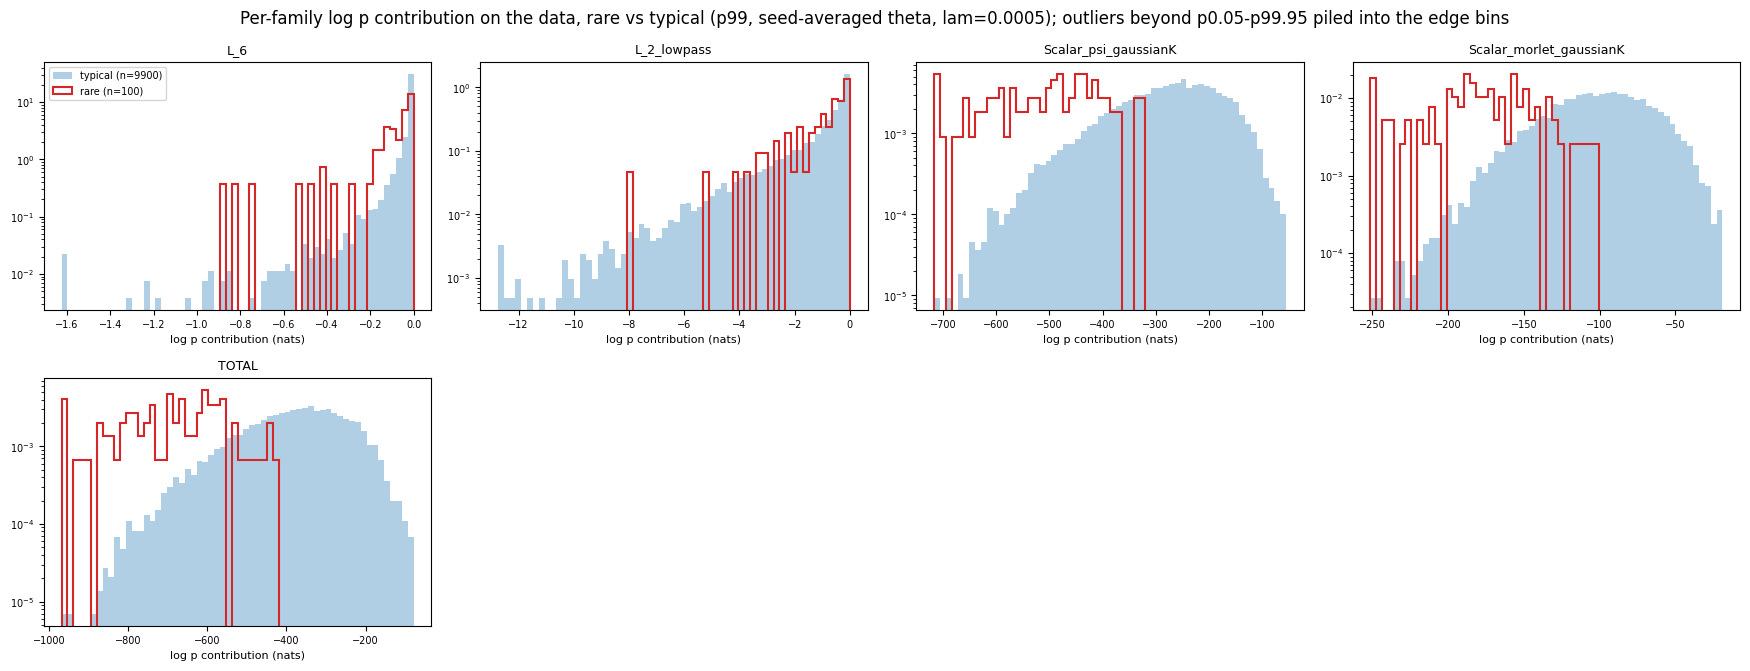

mean           std           skew          \
category                  rare typical  rare typical   rare typical   
family                                                                
L_2_lowpass             -0.997    -1.1  1.26    1.58  -2.57    -2.8   
L_6                     -0.102 -0.0212 0.162  0.0853  -3.13   -15.8   
Scalar_morlet_gaussianK   -180    -101  38.3    33.4 -0.632  -0.391   
Scalar_psi_gaussianK      -511    -279   110    99.5  -0.56  -0.617   
TOTAL                     -692    -381   144     131 -0.579  -0.565   

                        excess kurtosis                p1              p99  \
category                           rare typical      rare typical     rare   
family                                                                       
L_2_lowpass                        9.19    12.3     -5.28   -7.37 -0.00133   
L_6                                10.4     398    -0.826  -0.308 -0.00254   
Scalar_morlet_gaussianK           0.855   0.102      -261    -186     -108   
Scalar_psi_gaussianK            -0.0725   0.268      -762    -548     -327   
TOTAL                             0.244   0.204 -1.01e+03    -733     -445   

                                   
category                  typical  
family                             
L_2_lowpass             -0.000366  
L_6                     -4.01e-06  
Scalar_morlet_gaussianK     -35.4  
Scalar_psi_gaussianK         -103  
TOTAL                        -143

In [56]:
# Shape of each family's log p contribution C_F(x) = theta_F . phi_F(x) on the data (x1),
# seed-averaged theta, rare vs typical overlaid. density=True: the two categories have very
# different sizes (n printed in the legend), so compare shapes, not counts. Each panel has its own x-range
from scipy import stats

fams = list(ranges_with_total.keys())            # all families + TOTAL
n_cols = 4
n_rows = math.ceil(len(fams) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.4 * n_cols, 3.4 * n_rows), squeeze=False)

shape_rows = []
for i, F in enumerate(fams):
    ax = axes[i // n_cols][i % n_cols]
    vals = C_bar[F]
    lo, hi = np.percentile(vals, [0.05, 99.95])   # clip extreme outliers from the bin range only
    edges = np.linspace(lo, hi, 61)
    for cat, idx in category_indices.items():
        v = vals[idx]
        ax.hist(np.clip(v, lo, hi), bins=edges, density=True, histtype='stepfilled' if cat == 'typical' else 'step',
                color=category_colors[cat], alpha=0.35 if cat == 'typical' else 1.0, lw=1.5,
                label=f'{cat} (n={len(v)})')
        shape_rows.append({'family': F, 'category': cat, 'mean': v.mean(), 'std': v.std(ddof=1),
                           'skew': stats.skew(v), 'excess kurtosis': stats.kurtosis(v),
                           'p1': np.percentile(v, 1), 'p99': np.percentile(v, 99)})
    ax.set_yscale('log')
    ax.set_title(F, fontsize=9)
    ax.set_xlabel('log p contribution (nats)', fontsize=8)
    ax.tick_params(labelsize=7)
axes[0][0].legend(fontsize=7)
for j in range(len(fams), n_rows * n_cols):
    axes[j // n_cols][j % n_cols].axis('off')
fig.suptitle(f'Per-family log p contribution on the data, rare vs typical ({P_LABEL}, seed-averaged theta, {LAM_LABEL}); '
             'outliers beyond p0.05-p99.95 piled into the edge bins')
fig.tight_layout(); plt.show()

shape_df = pd.DataFrame(shape_rows).set_index(['family', 'category'])
display(shape_df.unstack('category'))

## 2. Robustness to the rare/typical threshold

Repeat the seed-mean `D` (no bootstrap) for each percentile in `ROBUSTNESS_PERCENTILES` (Knobs; `PERCENTILE` added), split on `x1` as above. The number of rare signals at each percentile is printed below the table.

In [57]:
percentiles = sorted({*ROBUSTNESS_PERCENTILES, PERCENTILE})
table2, n_rare_p = {}, {}
for p in percentiles:
    idx_typ_p, idx_rare_p, _ = extract_rare_typical(x1, criterion='percentile', percentile=p)
    n_rare_p[f'p{p:g}'] = len(idx_rare_p)
    table2[f'p{p:g}'] = [C[F][:, idx_rare_p].mean(axis=1).mean() - C[F][:, idx_typ_p].mean(axis=1).mean()
                        for F in family_names_all]
table2_df = pd.DataFrame(table2, index=family_names_all)
display(table2_df)
print('n_rare per percentile:', n_rare_p)

,p95,p99,p99.5
L_6,-0.0571,-0.0812,-0.098
L_2_lowpass,0.0331,0.099,0.249
Scalar_psi_gaussianK,-190,-232,-273
Scalar_morlet_gaussianK,-64.3,-78.5,-92.5
TOTAL,-254,-310,-365


n_rare per percentile: {'p95': 500, 'p99': 100, 'p99.5': 50}


## 3. Continuous version (no split)

Extremeness `e_i` = max over time of |lag-1 increment| of `x1[i]` (same definition and units as the split). Per family: centered log p contribution vs `e_i` (log x-axis), with the `idx_rare` signals highlighted. Table: Spearman rank correlation per family.

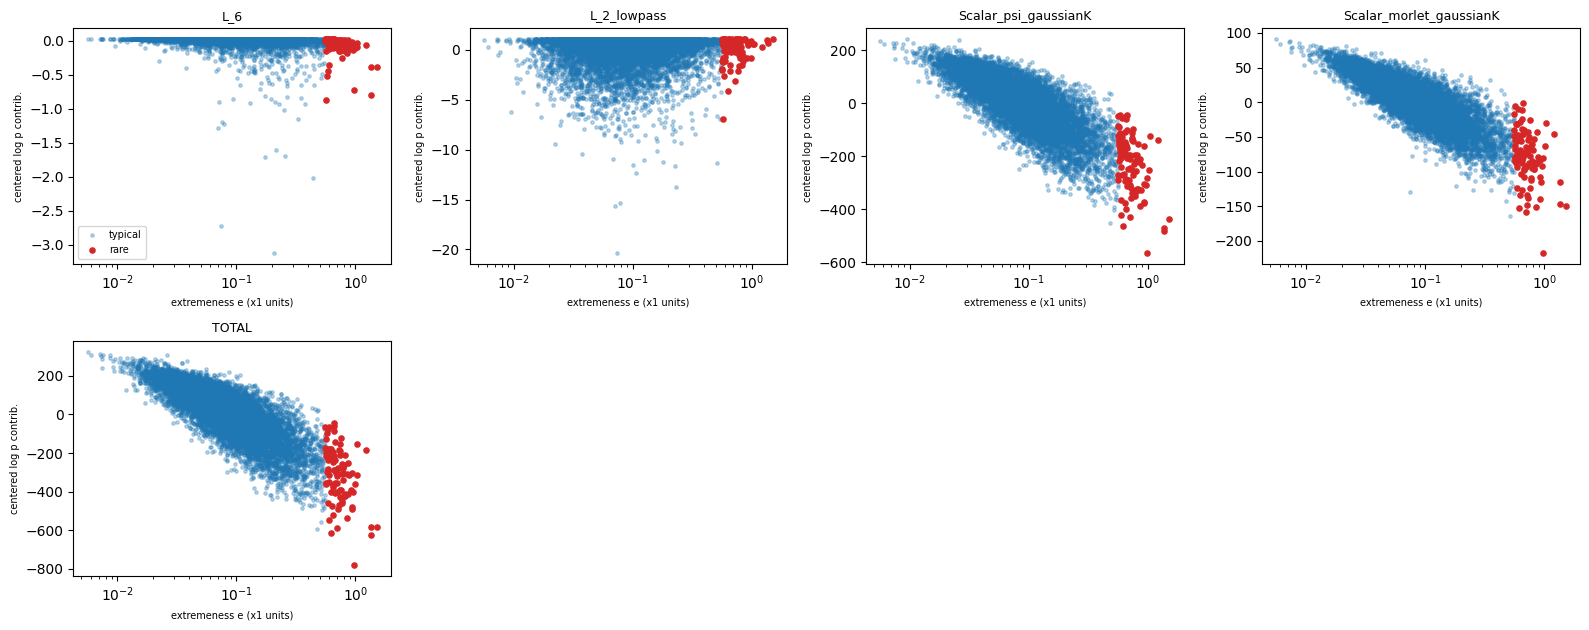

,family,spearman_rho
0,L_6,-0.49
1,L_2_lowpass,-0.01
2,Scalar_psi_gaussianK,-0.78
3,Scalar_morlet_gaussianK,-0.815
4,TOTAL,-0.801


In [58]:
accel = compute_acceleration(x1)  # (n1, 1, M-1)
e = accel.abs().amax(dim=(1, 2)).cpu().numpy()  # (n1,) extremeness

n_cols = 4
n_rows = math.ceil(len(family_names_all) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.2 * n_rows), squeeze=False)
mask_rare = np.zeros(n1, dtype=bool)
mask_rare[idx_rare] = True

spearman_rows = []
for i, F in enumerate(family_names_all):
    ax = axes[i // n_cols][i % n_cols]
    y = C_bar[F] - C_bar[F].mean()
    ax.scatter(e[~mask_rare], y[~mask_rare], s=6, alpha=0.3, color=category_colors['typical'], label='typical')
    ax.scatter(e[mask_rare], y[mask_rare], s=14, color=category_colors['rare'], label='rare')
    ax.set_xscale('log')
    ax.set_title(F, fontsize=9)
    ax.set_xlabel('extremeness e (x1 units)', fontsize=7)
    ax.set_ylabel('centered log p contrib.', fontsize=7)
    # Spearman = Pearson correlation of ranks (avoids a scipy import)
    rho = np.corrcoef(pd.Series(e).rank(), pd.Series(C_bar[F]).rank())[0, 1]
    spearman_rows.append({'family': F, 'spearman_rho': rho})
axes[0][0].legend(fontsize=7)
for j in range(len(family_names_all), n_rows * n_cols):
    axes[j // n_cols][j % n_cols].axis('off')
fig.tight_layout()
plt.show()

display(pd.DataFrame(spearman_rows))

## 4. Compensation between families

Correlation matrix of the families' log p contributions (seed-averaged $\theta$) across all `n1` signals. Then the sign-aware variance decomposition $\sum_{F\neq G}\mathrm{Cov}(C_F,C_G)=\mathrm{Var}(\mathrm{TOTAL})-\sum_F\mathrm{Var}(C_F)$: positive means the cross-family covariances **add** variance, negative means they **remove** it (compensation). The largest pairwise terms $2\,\mathrm{Cov}(C_F,C_G)$ are listed with their sign.

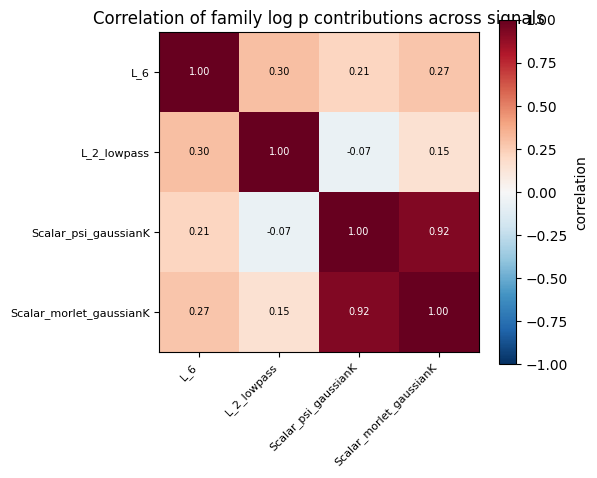

Var(TOTAL) = 1.812e+04
sum_F Var(C_F) = 1.164e+04
sum_(F!=G) Cov(C_F, C_G) = Var(TOTAL) - sum_F Var(C_F) = 6480  ->  cross-family covariance adds 55.7% of sum_F Var(C_F)
3 largest pairwise terms 2*Cov(C_F, C_G) by |value| (+ reinforces, - compensates):
  +6480   Scalar_psi_gaussianK & Scalar_morlet_gaussianK
  -21.87   L_2_lowpass & Scalar_psi_gaussianK
  +16.35   L_2_lowpass & Scalar_morlet_gaussianK


In [59]:
fam_only = list(family_ranges.keys())
C_mat = np.stack([C_bar[F] for F in fam_only], axis=0)  # (n_families, n1)
corr = np.corrcoef(C_mat)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(fam_only))); ax.set_xticklabels(fam_only, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(len(fam_only))); ax.set_yticklabels(fam_only, fontsize=8)
for i in range(len(fam_only)):
    for j in range(len(fam_only)):
        ax.text(j, i, f'{corr[i, j]:.2f}', ha='center', va='center', fontsize=7,
                color='white' if abs(corr[i, j]) > 0.5 else 'black')
fig.colorbar(im, ax=ax, label='correlation')
ax.set_title('Correlation of family log p contributions across signals')
fig.tight_layout()
plt.show()

var_total = C_bar['TOTAL'].var(ddof=1)
var_sum_families = sum(C_bar[F].var(ddof=1) for F in fam_only)
cross_cov = var_total - var_sum_families   # = sum_{F != G} Cov(C_F, C_G)
print(f"Var(TOTAL) = {var_total:.4g}")
print(f"sum_F Var(C_F) = {var_sum_families:.4g}")
print(f"sum_(F!=G) Cov(C_F, C_G) = Var(TOTAL) - sum_F Var(C_F) = {cross_cov:.4g}  ->  cross-family covariance "
      f"{'adds' if cross_cov > 0 else 'removes'} {100 * abs(cross_cov) / var_sum_families:.1f}% of sum_F Var(C_F)")

cov_fam = np.cov(C_mat, ddof=1)
pair_terms = [(2 * cov_fam[i, j], fam_only[i], fam_only[j])
              for i in range(len(fam_only)) for j in range(i + 1, len(fam_only))]
print("3 largest pairwise terms 2*Cov(C_F, C_G) by |value| (+ reinforces, - compensates):")
for term, F, G in sorted(pair_terms, key=lambda t: -abs(t[0]))[:3]:
    print(f"  {term:+.4g}   {F} & {G}")

## 5. Residual variance: which families are irreplaceable?

With $p_\theta\propto e^{+\theta^\top\varphi}$, write $C_F(x)=\theta_F^\top\varphi_F(x)$, so $\log p_\theta=\sum_F C_F-\log Z(\theta)$. The raw variance $\mathrm{Var}[C_F]$ overstates a family's role when other families can reproduce part of $C_F$ (compensation, near-collinear features). We therefore measure the part they cannot reproduce:
$$R_F=\min_\beta\,\mathrm{Var}\big[C_F-\beta^\top\varphi_{\bar F}\big].$$

**Why this quantity.** For an exponential family, $\mathrm{KL}(p_\theta\|p_{\theta+\delta})=\tfrac12\,\delta^\top\Sigma\,\delta+O(|\delta|^3)$ with $\Sigma=\mathrm{Cov}_{p_\theta}[\varphi]$ (standard). Removing $F$ ($\delta_F=-\theta_F$) and optimally refitting the other couplings costs, to second order, $\tfrac12 R_F$ (a Schur complement of $\Sigma$). So $R_F$ measures the information lost by dropping $F$. Computed on the rare subset, it is the same statement for $p_\theta(x\mid x\in\text{rare})$.

We report three levels, $\mathrm{Var}[C_F]\ \ge\ R_F^{\rm fam}\ \ge\ R_F$, where $R_F^{\rm fam}$ only lets other families rescale ($\beta$ acting on the $C_G$, $G\neq F$), and $R_F$ allows a full refit on the other families' features (ridge, cross-fitted). For a pair, $\mathrm{Var}[C_F+C_G]$ upper-bounds the cost of removing both: if small, $F$ and $G$ are **redundant** (each can replace the other), not individually irrelevant.

**Caveats.** (i) Variances are computed on data, a proxy for the model covariance. (ii) The expansion is local: it underestimates the cost of confining terms whose removal breaks normalizability; for such terms (plausibly L_6) small variance does not mean irrelevance. (iii) Small $R_F$ means *replaceable*, not *physically meaningless*.

*Implementation.* Both $R_F^{\rm fam}$ (least squares) and $R_F$ (ridge) are 2-fold cross-fitted on the same random split of each set: fit on one half, take residuals on the other, swap, pool. Ridge regressors are standardized on the training fold, with penalty $n_{\rm train}\,\lambda\,|\beta|^2$ and one $\lambda$ chosen on `all` (printed below).

In [60]:
sets = {'all': np.arange(n1), 'typical': np.array(idx_typical), 'rare': np.array(idx_rare)}
rng = np.random.default_rng(0)   # assumption: random 2-fold split, fixed seed
folds = {name: np.array_split(rng.permutation(idx), 2) for name, idx in sets.items()}
C64 = {F: C[F].astype(np.float64) for F in fam_only}          # (n_seeds, n1), from the energy cell
# regressors: the other families' features, from each seed's own phi (all the same object if PHI_SHARED)
X_notF = {k: {F: np.delete(phi_by_seed[k], np.r_[a:b], axis=1) for F, (a, b) in family_ranges.items()}
          for k in (seed_keys if not PHI_SHARED else [REFERENCE_SEED])}
X_of = lambda s, F: X_notF[seed_keys[s] if not PHI_SHARED else REFERENCE_SEED][F]

def crossfit_resid_var(X, Y, fold_pair, lam):
    """2-fold cross-fitted residual variance of Y (n1, k) regressed on X (n1, p) with intercept,
    columns of X standardized on the training fold; lam=None -> least squares, else ridge with
    penalty n_train * lam * |beta|^2. fold_pair holds row indices into X/Y. Returns (k,)."""
    resid = []
    for tr, te in (fold_pair, fold_pair[::-1]):
        mu, sd = X[tr].mean(0), X[tr].std(0)
        sd[sd == 0] = 1.0
        Xtr, Xte = (X[tr] - mu) / sd, (X[te] - mu) / sd
        ybar = Y[tr].mean(0)
        pen = 0.0 if lam is None else len(tr) * lam
        beta = np.linalg.solve(Xtr.T @ Xtr + pen * np.eye(X.shape[1]), Xtr.T @ (Y[tr] - ybar))
        resid.append(Y[te] - ybar - Xte @ beta)
    return np.concatenate(resid).var(axis=0, ddof=1)

def r_feat(F, set_name, lam):
    """(n_seeds,) ridge residual variance of C_F on the other families' features."""
    if PHI_SHARED:   # one regression, every seed a column of Y
        return crossfit_resid_var(X_of(0, F), C64[F].T, folds[set_name], lam)
    return np.array([crossfit_resid_var(X_of(s, F), C64[F][s][:, None], folds[set_name], lam)[0]
                     for s in range(n_seeds)])

def var_raw(F, set_name):
    return C64[F][:, sets[set_name]].var(axis=1, ddof=1)       # (n_seeds,)

# Ridge lambda: one value for all families, minimizing mean_{F, seeds} R_feat/var_raw on 'all'.
lam_grid = np.logspace(-6, 0, 7)
lam_score = [np.mean([(r_feat(F, 'all', lam) / var_raw(F, 'all')).mean() for F in fam_only]) for lam in lam_grid]
lam_ridge = lam_grid[int(np.argmin(lam_score))]
print("mean R_feat/var_raw on 'all' per lambda: "
      + ", ".join(f"{lam:.0e}: {s:.4g}" for lam, s in zip(lam_grid, lam_score)))
print(f"ASSUMPTION: ridge lambda fixed at {lam_ridge:.0e} for every set/family"
      + ("  (WARNING: at the edge of the grid)" if lam_ridge in (lam_grid[0], lam_grid[-1]) else ""))

res = {}   # (set, F) -> per-seed arrays
for set_name in sets:
    for F in fam_only:
        others = [G for G in fam_only if G != F]
        r_fam = np.array([crossfit_resid_var(np.stack([C64[G][s] for G in others], axis=1),
                                             C64[F][s][:, None], folds[set_name], None)[0]
                          for s in range(n_seeds)])
        rf = r_feat(F, set_name, lam_ridge)
        v = var_raw(F, set_name)
        res[set_name, F] = {'var_raw': v, 'R_fam': r_fam, 'R_feat': rf, 'R_feat/var_raw': rf / v}

# Bootstrap over rare signals, seed-averaged C_bar and the reference seed's features, for
# R_feat/var_raw. Resampled within each fold, so a duplicated signal never sits in both halves.
rng = np.random.default_rng(BOOT_SEED)
n_boot = N_BOOT
f0, f1 = folds['rare']
boot_ratio = np.empty((n_boot, len(fam_only)))
for bi in range(n_boot):
    bfolds = (rng.choice(f0, len(f0)), rng.choice(f1, len(f1)))
    bidx = np.concatenate(bfolds)
    for j, F in enumerate(fam_only):
        y = C_bar[F].astype(np.float64)[:, None]
        boot_ratio[bi, j] = crossfit_resid_var(X_of(0, F), y, bfolds, lam_ridge)[0] / y[bidx].var(ddof=1)
rare_point = [crossfit_resid_var(X_of(0, F), C_bar[F].astype(np.float64)[:, None], folds['rare'], lam_ridge)[0]
              / C_bar[F][idx_rare].var(ddof=1) for F in fam_only]

sd = lambda a: a.std(ddof=1) if len(a) > 1 else np.nan
quantities = ['var_raw', 'R_fam', 'R_feat', 'R_feat/var_raw']
table_rv = pd.DataFrame({(set_name, q): [f"{res[set_name, F][q].mean():.3g} ± {sd(res[set_name, F][q]):.2g}"
                                         for F in fam_only]
                         for set_name in sets for q in quantities}, index=fam_only)
table_rv[('rare', 'R_feat/var_raw, mean theta ± boot SE')] = [
    f"{p:.3g} ± {se:.2g}" for p, se in zip(rare_point, boot_ratio.std(axis=0, ddof=1))]
print(f"mean ± std across {n_seeds} seeds; set sizes: " + ", ".join(f"{k} = {len(v)}" for k, v in sets.items())
      + f"; bootstrap: {n_boot} resamples of the rare signals")
display(table_rv)

n_viol = sum(int((r['R_fam'] > r['var_raw']).sum() + (r['R_feat'] > r['R_fam']).sum()) for r in res.values())
print(f"(set, family, seed) cases breaking var_raw >= R_fam >= R_feat (estimation noise): "
      f"{n_viol} of {2 * len(res) * n_seeds} comparisons")

mean R_feat/var_raw on 'all' per lambda: 1e-06: 0.1177, 1e-05: 0.1182, 1e-04: 0.1211, 1e-03: 0.1256, 1e-02: 0.138, 1e-01: 0.1614, 1e+00: 0.232
ASSUMPTION: ridge lambda fixed at 1e-06 for every set/family  (WARNING: at the edge of the grid)
mean ± std across 5 seeds; set sizes: all = 10000, typical = 9900, rare = 100; bootstrap: 1000 resamples of the rare signals


all                                    \
                               var_raw           R_fam            R_feat   
L_6                      0.014 ± 0.017  0.0117 ± 0.013  0.00442 ± 0.0045   
L_2_lowpass                 3.16 ± 2.5      1.67 ± 1.1    0.0147 ± 0.012   
Scalar_psi_gaussianK     1.05e+04 ± 91   1.11e+03 ± 31        571 ± 0.44   
Scalar_morlet_gaussianK  1.19e+03 ± 41       123 ± 3.2       46.9 ± 0.22   

                                                   typical                  \
                            R_feat/var_raw         var_raw           R_fam   
L_6                          0.372 ± 0.064  0.0137 ± 0.017  0.0114 ± 0.013   
L_2_lowpass              0.00464 ± 1.5e-14      3.17 ± 2.5      1.65 ± 1.1   
Scalar_psi_gaussianK      0.0545 ± 0.00047   9.92e+03 ± 91   1.09e+03 ± 29   
Scalar_morlet_gaussianK    0.0394 ± 0.0014   1.13e+03 ± 42       120 ± 3.3   

                                                                      rare  \
                                   R_feat    R_feat/var_raw        var_raw   
L_6                      0.00453 ± 0.0046     0.392 ± 0.086  0.035 ± 0.026   
L_2_lowpass              0.00721 ± 0.0057   0.00228 ± 2e-15     2.02 ± 1.6   
Scalar_psi_gaussianK           524 ± 0.16  0.0528 ± 0.00048   1.2e+04 ± 61   
Scalar_morlet_gaussianK       43.3 ± 0.15   0.0384 ± 0.0014  1.47e+03 ± 29   

                                                                 \
                                      R_fam              R_feat   
L_6                          0.0337 ± 0.027      0.0777 ± 0.042   
L_2_lowpass                      2.74 ± 2.1          5.67 ± 4.5   
Scalar_psi_gaussianK     3.48e+03 ± 1.8e+02  1.16e+07 ± 2.3e+05   
Scalar_morlet_gaussianK            453 ± 28  1.37e+03 ± 1.2e+02   

                                                                              
                         R_feat/var_raw R_feat/var_raw, mean theta ± boot SE  
L_6                          2.4 ± 0.37                           2.49 ± 1.9  
L_2_lowpass              2.81 ± 2.7e-09                           2.81 ± 6.4  
Scalar_psi_gaussianK           966 ± 15                        967 ± 2.9e+02  
Scalar_morlet_gaussianK   0.933 ± 0.093                          0.933 ± 5.9

(set, family, seed) cases breaking var_raw >= R_fam >= R_feat (estimation noise): 27 of 120 comparisons


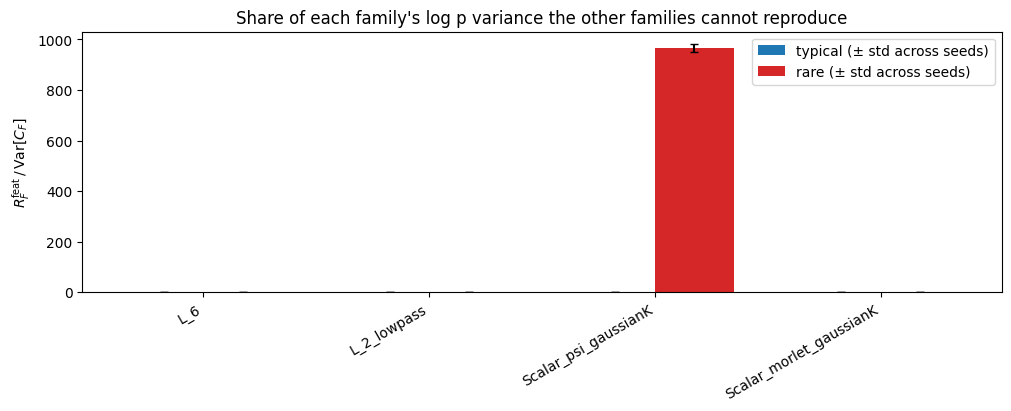

typical: lowest R_feat/var_raw (most replaceable) = L_2_lowpass (0.00228); highest (least replaceable) = L_6 (0.392)
rare: lowest R_feat/var_raw (most replaceable) = Scalar_morlet_gaussianK (0.933); highest (least replaceable) = Scalar_psi_gaussianK (966)

Rare set: Var[C_F + C_G] / (Var[C_F] + Var[C_G])


,L_6,L_2_lowpass,Scalar_psi_gaussianK,Scalar_morlet_gaussianK
L_6,NaN,1.03,1,1
L_2_lowpass,1.03,NaN,0.999,1
Scalar_psi_gaussianK,1,0.999,NaN,1.53
Scalar_morlet_gaussianK,1,1,1.53,NaN


In [61]:
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
xpos = np.arange(len(fam_only))
for i, set_name in enumerate(['typical', 'rare']):
    ratio = np.stack([res[set_name, F]['R_feat/var_raw'] for F in fam_only])   # (n_families, n_seeds)
    ax.bar(xpos + (i - 0.5) * 0.35, ratio.mean(1), 0.35, yerr=ratio.std(1, ddof=1), capsize=3,
           color=category_colors[set_name], label=f'{set_name} (± std across seeds)')
ax.set_xticks(xpos); ax.set_xticklabels(fam_only, rotation=30, ha='right')
ax.set_ylabel(r'$R_F^{\rm feat}\,/\,\mathrm{Var}[C_F]$')
ax.set_title('Share of each family\'s log p variance the other families cannot reproduce')
ax.legend()
plt.show()

for set_name in ['typical', 'rare']:
    r = {F: res[set_name, F]['R_feat/var_raw'].mean() for F in fam_only}
    order = sorted(r, key=r.get)
    print(f"{set_name}: lowest R_feat/var_raw (most replaceable) = {order[0]} ({r[order[0]]:.3g}); "
          f"highest (least replaceable) = {order[-1]} ({r[order[-1]]:.3g})")

# Pair check on the rare set, seed-averaged theta: Var[C_F + C_G] / (Var[C_F] + Var[C_G])
# (= 1 if uncorrelated, << 1 means F and G compensate each other; diagonal left blank).
C_rare = np.stack([C_bar[F][idx_rare] for F in fam_only]).astype(np.float64)
v_rare = C_rare.var(axis=1, ddof=1)
pair_ratio = pd.DataFrame([[np.nan if i == j else (C_rare[i] + C_rare[j]).var(ddof=1) / (v_rare[i] + v_rare[j])
                            for j in range(len(fam_only))] for i in range(len(fam_only))],
                          index=fam_only, columns=fam_only)
print("\nRare set: Var[C_F + C_G] / (Var[C_F] + Var[C_G])")
display(pair_ratio)

## 6. Model samples

Each seed's final samples (`saved_results/samples/<config>.pt`), with φ from that seed's own fitted potentials and paired with that seed's θ.

In [62]:
sample_path = {}   # seed_key -> path of that seed's samples file
for key in seed_keys:
    p = root / "saved_results" / "samples" / config_by_seed[key]
    p_pt = p.with_name(p.name + ".pt")
    path = p_pt if p_pt.exists() else (p if p.exists() else None)
    if path is not None:
        sample_path[key] = path
print(f"{len(sample_path)}/{len(seed_keys)} seeds have a samples file")
assert sample_path, 'no samples file found: section 6 needs at least one'

model_norm_checked = False
needs_norm = None
C_model = {}   # seed_key -> {family: (n_model,) array}, includes 'TOTAL'
e_model = {}   # seed_key -> (n_model,) extremeness, same lag-1/max|.| definition and units as the split on x1

for key, path in sample_path.items():
    x_final = torch.load(path, map_location='cpu').reshape(-1, 1, M)

    if not model_norm_checked:
        m, s = x_final.mean().item(), x_final.std().item()
        needs_norm = not (abs(m) < 0.05 and abs(s - 1) < 0.05)
        print(f"model samples {tuple(x_final.shape)}: mean={m:.4g} std={s:.4g} -> "
              f"{'applying' if needs_norm else 'skipping'} normalize() (checked on {key} only)")
        model_norm_checked = True

    x_model = normalize(x_final) if needs_norm else x_final   # CPU; same tensor for phi and extremeness
    phi_model = compute_phi_X(potentials_by_seed[key], x_model.to(device)).detach().cpu().double().numpy()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    s_idx = seed_keys.index(key)
    c_this = {F: phi_model[:, a:b] @ reg_all_np[s_idx, a:b] for F, (a, b) in family_ranges.items()}
    c_this['TOTAL'] = sum(c_this.values())
    C_model[key] = c_this

    accel_model = compute_acceleration(x_model)
    e_model[key] = accel_model.abs().amax(dim=tuple(range(1, accel_model.ndim))).numpy()

print(f"Computed model-sample phi/log-p contributions for {len(C_model)} seeds.")

5/5 seeds have a samples file
model samples (10000, 1, 256): mean=0.003133 std=0.9998 -> skipping normalize() (checked on seed900 only)
Computed model-sample phi/log-p contributions for 5 seeds.


### 6a. Data vs model: TOTAL log p contribution and per-family std

Same-seed theta on data (from section 1's `C`) vs on that seed's model samples, pooled across seeds.

L_6                                           data std=    0.1192   model std=    0.1331
L_2_lowpass                                   data std=     1.864   model std=     1.865
Scalar_psi_gaussianK                          data std=     102.4   model std=     84.57
Scalar_morlet_gaussianK                       data std=     34.64   model std=      29.7


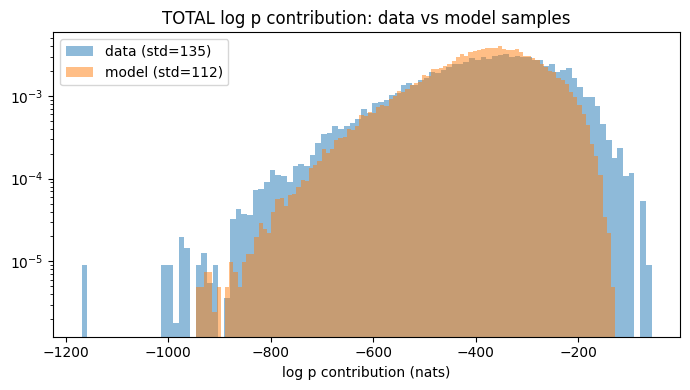

TOTAL mean: data = -384.5, model = -390.4 (each seed's own theta, pooled over 5 seeds)


In [63]:
model_keys = list(C_model.keys())
for F in family_names_all:
    data_vals = np.concatenate([C[F][seed_keys.index(k)] for k in model_keys])
    model_vals = np.concatenate([C_model[k][F] for k in model_keys])
    if F == 'TOTAL':
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.hist(data_vals, bins=100, density=True, alpha=0.5, color='tab:blue',
                label=f'data (std={data_vals.std():.3g})')
        ax.hist(model_vals, bins=100, density=True, alpha=0.5, color='tab:orange',
                label=f'model (std={model_vals.std():.3g})')
        ax.set_yscale('log'); ax.legend()
        ax.set_xlabel('log p contribution (nats)')
        ax.set_title('TOTAL log p contribution: data vs model samples')
        fig.tight_layout(); plt.show()
        print(f"TOTAL mean: data = {data_vals.mean():.4g}, model = {model_vals.mean():.4g} "
              f"(each seed's own theta, pooled over {len(model_keys)} seeds)")
    else:
        print(f"{F:45s} data std={data_vals.std():10.4g}   model std={model_vals.std():10.4g}")

**Caveat.** With `THETA_SOURCE = 'theta_t'` (the default here, since there is no offline solve yet) the θ paired with the samples is the one that drove the sampler at the last step. If you switch to `'theta_reg'` once an offline solve exists, the MGD samples are not guaranteed to be samples of $p_{\Theta_{\rm reg}}$: $\Theta_{\rm reg}$ is a separate regularised fit (and depends on `LAM`), and a gap between the data and model TOTAL means is read with that in mind.


### 6b. Rare fraction: model vs data, same cutoff

Apply the data cutoff `cutoff_rare` (at `PERCENTILE`, plus p95/p99 for reference) (from the split on `x1`) to the model samples' max |lag-1 increment|, computed in the same normalized units.

In [64]:
data_rare_frac = len(idx_rare) / n1
cut_rows = [(P_LABEL, cutoff_rare, data_rare_frac)]
for p in (95, 99):
    if p != PERCENTILE:
        cut_p = extract_rare_typical(x1, criterion='percentile', percentile=p)[2]['cutoff']
        cut_rows.append((f'p{p}', cut_p, (e_split > cut_p).mean()))

print("CAVEAT: cutoffs and both extremeness values are in x1's normalized units; model samples are taken to "
      "already be in those units (mean/std checked on one seed, in the loading cell above).")
rows = []
for name, cut, data_frac in cut_rows:
    per_seed = np.array([(e_model[k] > cut).mean() for k in C_model])
    pooled = np.concatenate([e_model[k] for k in C_model])
    rows.append({'data cutoff': name, 'cutoff (x1 units)': cut, 'data fraction': data_frac,
                 'model fraction (pooled)': (pooled > cut).mean(),
                 'model n above (pooled)': int((pooled > cut).sum()), 'model n (pooled)': len(pooled),
                 'model fraction, std across seeds': per_seed.std(ddof=1) if len(per_seed) > 1 else np.nan})
display(pd.DataFrame(rows))

CAVEAT: cutoffs and both extremeness values are in x1's normalized units; model samples are taken to already be in those units (mean/std checked on one seed, in the loading cell above).


,data cutoff,cutoff (x1 units),data fraction,model fraction (pooled),model n above (pooled),model n (pooled),"model fraction, std across seeds"
0,p99,0.559,0.01,0.00066,33,50000,0.000152
1,p95,0.318,0.05,0.0525,2626,50000,0.000931


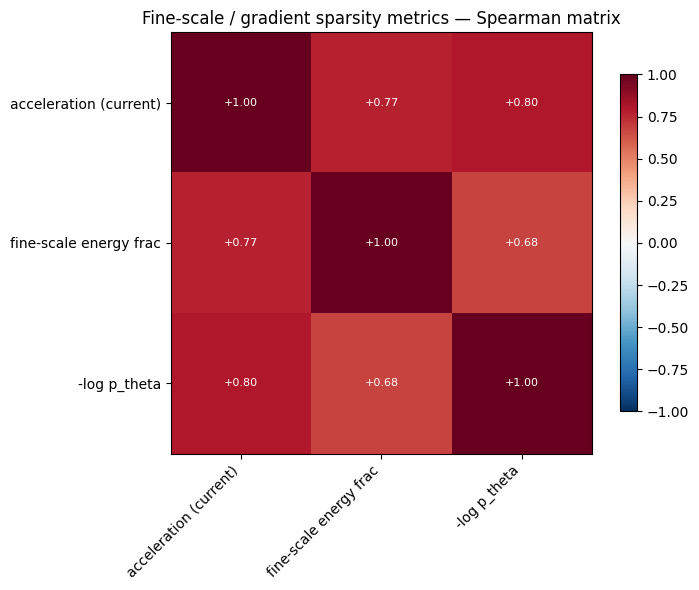

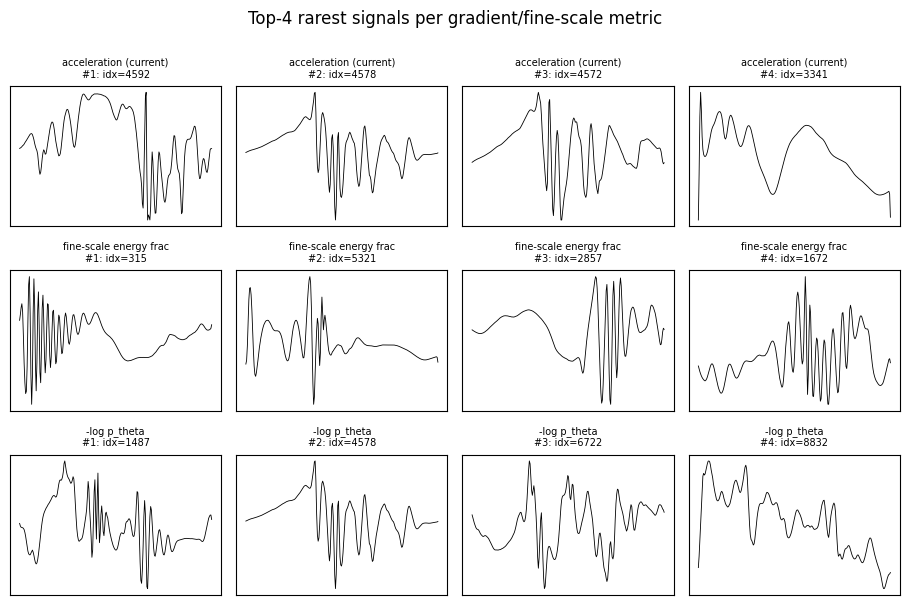

In [65]:
# --- Fine-scale / gradient sparsity metrics (fix for burst detection) ---
# A burst is sparse in POSITION but dense across fine scales → global PR/Hoyer
# miss it. These metrics look at gradient / fine-scale structure instead.
# per-signal arrays over all n1 data signals (names reused earlier in the notebook are redefined here)
x_np  = x1.detach().cpu().double().numpy().reshape(x1.shape[0], x1.shape[-1])          # (n1, T)
accel = compute_acceleration(x1).abs().amax(dim=(1, 2)).cpu().numpy()                    # (n1,) extremeness e, the rare/typical criterion
nlp   = -np.asarray(total_log_p_unnorm, dtype=float)                                     # (n1,) -log p, seed-averaged theta
assert x_np.shape[0] == accel.shape[0] == nlp.shape[0] == n1

# Rebuild wavelet decomposition keeping scale level info
from ortho_wavelet.ReadyToUseWavelets import Db_wavelets
wavelet = Db_wavelets(m=WAVELET_M, device=x1.device, mode='Periodic')
T = x1.shape[-1]; J = int(np.floor(np.log2(T)))
a = x1.reshape(x1.shape[0], T).to(x1.device)
level_blocks = []
with torch.no_grad():
    for _ in range(J):
        d, a = wavelet.decompose(a)
        level_blocks.append(d.detach().cpu().double().numpy())        # details level j
# level_blocks[0] = finest; level_blocks[-1] = coarsest detail

# gradient of x
dx = np.diff(x_np, axis=-1)
abs_dx = np.abs(dx)

# 1. Fine-scale energy fraction (finest N_FINE detail levels)
N_FINE = 3
e_fine = sum((b**2).sum(-1) for b in level_blocks[:N_FINE])
e_all  = sum((b**2).sum(-1) for b in level_blocks)
fine_energy_frac = e_fine / e_all

# # 2. Peakiness l_inf / l_2 of the gradient
# peakiness_grad = abs_dx.max(-1) / np.sqrt((dx**2).sum(-1))

# # 3. Fine-scale participation ratio (just the finest level)
# c_f = level_blocks[0]
# l1_f = np.abs(c_f).sum(-1); l2sq_f = (c_f**2).sum(-1); d_f = c_f.shape[-1]
# pr_fine = l1_f**2 / (d_f * l2sq_f)
# sparsity_pr_fine = -pr_fine

# # 4. Gradient flatness (kurtosis of Δx)
# flat_grad = (dx**4).mean(-1) / (dx**2).mean(-1)**2

# # 5. Hoyer sparsity on |Δx|
# d_dx = abs_dx.shape[-1]
# hoyer_grad = (np.sqrt(d_dx) - abs_dx.sum(-1) / np.sqrt((abs_dx**2).sum(-1))) / (np.sqrt(d_dx) - 1)

metrics_v2 = {
    'acceleration (current)':   accel,
    'fine-scale energy frac':   fine_energy_frac,
    #f'peakiness l∞/l2 of Δx':   peakiness_grad,
    #f'fine-level PR (level 0)': sparsity_pr_fine,
    #'gradient flatness':        flat_grad,
    #'Hoyer sparsity on |Δx|':   hoyer_grad,
    '-log p_theta':             nlp,
}
names2 = list(metrics_v2.keys())

# correlation matrix
M2 = np.zeros((len(names2), len(names2)))
for i, a_n in enumerate(names2):
    for j, b_n in enumerate(names2):
        M2[i,j] = spearmanr(metrics_v2[a_n], metrics_v2[b_n])[0]
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(M2, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(names2))); ax.set_yticks(range(len(names2)))
ax.set_xticklabels(names2, rotation=45, ha='right'); ax.set_yticklabels(names2)
for i in range(len(names2)):
    for j in range(len(names2)):
        ax.text(j, i, f'{M2[i,j]:+.2f}', ha='center', va='center',
                color='white' if abs(M2[i,j]) > 0.5 else 'black', fontsize=8)
ax.set_title('Fine-scale / gradient sparsity metrics — Spearman matrix')
fig.colorbar(im, ax=ax, shrink=0.8); fig.tight_layout(); plt.show()

# top-5 grid
TOP_K = 4
fig, axes = plt.subplots(len(names2), TOP_K, figsize=(2.3*TOP_K, 2.0*len(names2)), sharex=True)
for i, name in enumerate(names2):
    top_idx = np.argsort(-metrics_v2[name])[:TOP_K]
    for j, idx in enumerate(top_idx):
        ax = axes[i, j]
        ax.plot(x_np[idx], 'k-', lw=0.6)
        ax.set_title(f'{name[:24]}\n#{j+1}: idx={idx}', fontsize=7)
        ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f'Top-{TOP_K} rarest signals per gradient/fine-scale metric', y=1.00)
fig.tight_layout(); plt.show()

x1: M = 256 samples; 1 sample of x1 = 2 raw samples (subseries_len 512 -> target_len 256, wavelet low-pass)
a(t): ACF first zero at lag 9, integral correlation time = 4.11 samples
Theta = 5 samples of x1  (= 10 raw samples)
R1: median 0.00571, p99 0.18, max 1.2

Spearman of R1 with the other metrics:
  acceleration (current)       +0.995
  fine-scale energy frac       +0.748
  -log p_theta                 +0.794


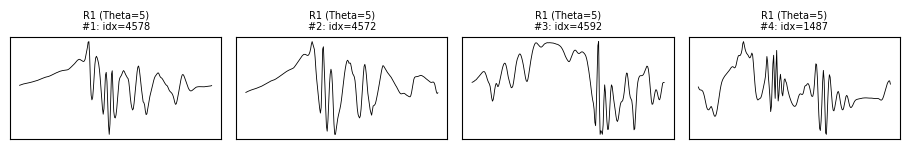

In [66]:
# --- R1(x) = max_t alpha_Theta(t),  alpha_Theta(t) = (1/Theta) * int_{t-Theta/2}^{t+Theta/2} |a(s)|^2 ds ---
# x1 is velocity (compute_acceleration = lag-1 velocity increment), so a(t) = x1(t+1) - x1(t).
# No physical dt in turbulence_1d_period.pt -> Theta is in SAMPLES OF x1.
# Boundaries as in compute_acceleration: no periodic wrap; only windows fully inside [0, M-1).
from scipy.stats import spearmanr

a_np  = compute_acceleration(x1).detach().cpu().double().numpy().reshape(n1, -1)   # (n1, M-1)
a2    = a_np ** 2

# -- time-resolution check: what one x1 sample is, and how long a(t) stays correlated --
down = int(cfg['subseries_len'] // cfg['target_len'])
print(f"x1: M = {M} samples; 1 sample of x1 = {down} raw samples "
      f"(subseries_len {cfg['subseries_len']} -> target_len {cfg['target_len']}, wavelet low-pass)")
ac = a_np - a_np.mean(-1, keepdims=True)
L  = ac.shape[-1]
F  = np.fft.rfft(ac, n=2 * L, axis=-1)
acf = np.fft.irfft(np.abs(F) ** 2, axis=-1)[:, :L].mean(0)
acf /= acf[0]
first_zero = int(np.argmax(acf <= 0)) if (acf <= 0).any() else L
tau_a = acf[:first_zero].sum()                           # integral correlation time of a(t), in samples
print(f"a(t): ACF first zero at lag {first_zero}, integral correlation time = {tau_a:.2f} samples")

# -- window: configurable; None -> smallest odd window >= the measured correlation time --
THETA_SAMPLES = None                                     # set an odd int to override (1 -> recovers max|a|^2 = current criterion)
if THETA_SAMPLES is None:
    THETA_SAMPLES = max(1, int(np.ceil(tau_a)) | 1)
assert THETA_SAMPLES % 2 == 1 and THETA_SAMPLES <= L, 'Theta must be odd (centred) and <= M-1'
print(f"Theta = {THETA_SAMPLES} samples of x1  (= {THETA_SAMPLES * down} raw samples)")

# -- centred moving average via cumulative sum, 'valid' windows only --
cs    = np.concatenate([np.zeros((n1, 1)), np.cumsum(a2, axis=-1)], axis=-1)
alpha = (cs[:, THETA_SAMPLES:] - cs[:, :-THETA_SAMPLES]) / THETA_SAMPLES        # (n1, L - Theta + 1), centred at i + (Theta-1)/2
R1    = alpha.max(-1)                                                            # (n1,) one score per trajectory
print(f"R1: median {np.median(R1):.3g}, p99 {np.percentile(R1, 99):.3g}, max {R1.max():.3g}")

# -- plug into the existing metric pipeline --
key_R1 = f'R1 (Theta={THETA_SAMPLES})'
metrics_v2[key_R1] = R1
print('\nSpearman of R1 with the other metrics:')
for name, v in metrics_v2.items():
    if name != key_R1:
        print(f'  {name:28s} {spearmanr(R1, v)[0]:+.3f}')

top_idx = np.argsort(-R1)[:TOP_K]
fig, axes = plt.subplots(1, TOP_K, figsize=(2.3 * TOP_K, 1.6))
for j, idx in enumerate(top_idx):
    axes[j].plot(x_np[idx], 'k-', lw=0.6)
    axes[j].set_title(f'{key_R1}\n#{j+1}: idx={idx}', fontsize=7)
    axes[j].set_xticks([]); axes[j].set_yticks([])
fig.tight_layout(); plt.show()

6 scales, periods 1/xi = [ 2.9  5.7 11.4 22.9 45.7 91.4] samples (M = 256)
R_ms: median 1.53, p99 32.6, max 140

Spearman of R_ms with the other metrics:
  acceleration (current)       +0.973
  fine-scale energy frac       +0.736
  -log p_theta                 +0.805
  R1 (Theta=5)                 +0.970


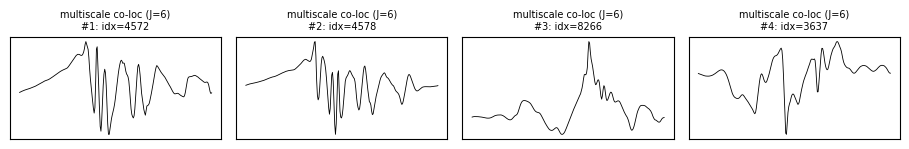

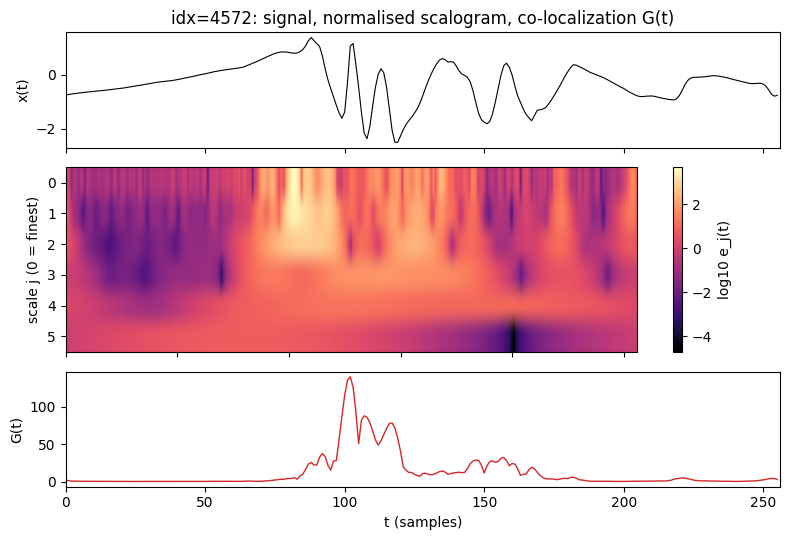

In [67]:
# --- Multiscale co-localization R_ms(x) = max_t G(t),  G(t) = exp( mean_j log e_j(t) ) ---
# e_j(t) = |w_j(t)|^2 / <|w_j|^2>_dataset, w_j = x * psi_j with analytic Morlet, one per octave (Q=1).
# Built here with the FFT, independent of the model's filters. Periodic boundaries (as the Db4 cells).
# Geometric mean over scales = "AND": G(t) is large only if ALL scales are excited at the same t.
XI_FINEST   = 0.35          # centre frequency of the finest wavelet, cycles/sample (Nyquist = 0.5)
SIGMA_FRAC  = 0.30          # Gaussian width in frequency = SIGMA_FRAC * xi  (~one-octave bandwidth)
DROP_COARSE = 2             # drop the largest octaves: only ~1-2 periods fit in M samples

J_all = int(np.floor(np.log2(M)))
J_ms  = J_all - DROP_COARSE
xis   = XI_FINEST * 2.0 ** -np.arange(J_ms)
print(f'{J_ms} scales, periods 1/xi = {np.round(1 / xis, 1)} samples (M = {M})')

Xf = np.fft.fft(x_np, axis=-1)                                     # (n1, M)
f  = np.fft.fftfreq(M)                                             # cycles/sample
log_e = np.zeros((n1, M))
e_scales = []                                                      # kept only for the top-1 check plot
for xi in xis:
    psi_hat = np.where(f > 0, np.exp(-(f - xi) ** 2 / (2 * (SIGMA_FRAC * xi) ** 2)), 0.0)   # analytic
    p   = np.abs(np.fft.ifft(Xf * psi_hat, axis=-1)) ** 2          # |w_j(t)|^2 = envelope^2, smooth
    e_j = p / p.mean()                                             # normalise by dataset mean at this scale
    log_e += np.log(e_j + 1e-12)
    e_scales.append(e_j)
G    = np.exp(log_e / J_ms)                                        # (n1, M)
R_ms = G.max(-1)                                                   # (n1,) one score per trajectory
print(f'R_ms: median {np.median(R_ms):.3g}, p99 {np.percentile(R_ms, 99):.3g}, max {R_ms.max():.3g}')

# -- plug into the metric pipeline --
key_ms = f'multiscale co-loc (J={J_ms})'
metrics_v2[key_ms] = R_ms
print('\nSpearman of R_ms with the other metrics:')
for name, v in metrics_v2.items():
    if name != key_ms:
        print(f'  {name:28s} {spearmanr(R_ms, v)[0]:+.3f}')

# -- top-K signals --
top_idx = np.argsort(-R_ms)[:TOP_K]
fig, axes = plt.subplots(1, TOP_K, figsize=(2.3 * TOP_K, 1.6))
for j, idx in enumerate(top_idx):
    axes[j].plot(x_np[idx], 'k-', lw=0.6)
    axes[j].set_title(f'{key_ms}\n#{j+1}: idx={idx}', fontsize=7)
    axes[j].set_xticks([]); axes[j].set_yticks([])
fig.tight_layout(); plt.show()

# -- check on the top-1: are all scales lit at the same time? --
i0 = top_idx[0]
fig, axes = plt.subplots(3, 1, figsize=(8, 5.5), sharex=True, gridspec_kw={'height_ratios': [1, 1.6, 1]})
axes[0].plot(x_np[i0], 'k-', lw=0.8); axes[0].set_ylabel('x(t)')
im = axes[1].imshow(np.log10(np.stack([e[i0] for e in e_scales]) + 1e-12), aspect='auto', cmap='magma',
                    extent=[0, M, J_ms - 0.5, -0.5])
axes[1].set_ylabel('scale j (0 = finest)'); fig.colorbar(im, ax=axes[1], label='log10 e_j(t)')
axes[2].plot(G[i0], 'tab:red', lw=1); axes[2].set_ylabel('G(t)'); axes[2].set_xlabel('t (samples)')
axes[0].set_title(f'idx={i0}: signal, normalised scalogram, co-localization G(t)')
fig.tight_layout(); plt.show()